# AISHE analysis
**Note:** For reproducibility:



1.   First make a copy of the notebook and work on the copy
2.   Check these things: paths name, file names, APIs IDs, and customize them according to your environment
3.   After doing a major data operation, you can push your final version here: https://github.com/GaelKBertrand/scholar_info_append






### Mounting Google Drive as a working director

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Analysis

## 2019

### 2019 C

Load the dataset

In [1]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt

# Upload the file
uploaded = files.upload()

# Get the file name
file_name = list(uploaded.keys())[0]

# Load the dataset
df = pd.read_csv(file_name)


KeyboardInterrupt: 

In [324]:
import pandas as pd
# Define the path to your file in Colab's storage
#file_path = '/content/Block-6-college_all_enrollment.csv'  # Update with your actual file name
#file_path = '/content/2019/Block-6-Enrollment_detais.csv'
file_path = '/content/2019/Block 6 - Category wise student enrollment.csv'

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

In [340]:
import pandas as pd
# Define the path to your file in Colab's storage
#file_path = '/content/2018/Block-6-all-enrollment_U.csv'  # Update with your actual file name
file_path = '/content/2018/Block-6-all-enrollment.csv'
#file_path = '/content/2018/Block-6-enrollment_details_S.csv'

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

<ipython-input-340-493d962fba7e>:8: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [341]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
1,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
2,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
3,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
4,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,236,136,0


In [342]:
# Check the unique values for the specified columns
institute_type_unique = df['institute_type'].unique()
management_unique = df['management'].unique()
#university_type_unique = df['university_type'].unique()
state_unique = df['state'].unique()
level_unique = df['level'].unique()

# Printing the unique values
print("Unique values in 'institute_type':", institute_type_unique)
print("Unique values in 'management':", management_unique)
#print("Unique values in 'university_type':", university_type_unique)
print("Unique values in 'state':", state_unique)
print("Unique values in 'level':", level_unique)


Unique values in 'institute_type': ['Affiliated College' 'Constituent / University College'
 'PG Center / Off-Campus Center' 'Recognized Center']
Unique values in 'management': ['Private Aided' 'Private Un-Aided' 'State Government' 'Local Body'
 'University' 'Central Government']
Unique values in 'state': ['Gujarat' 'Karnataka' 'Uttarakhand' 'Tamil Nadu' 'Puducherry'
 'Maharashtra' 'Bihar' 'Punjab' 'Haryana' 'Assam' 'Uttar Pradesh' 'Odisha'
 'Himachal Pradesh' 'Kerala' 'West Bengal' 'Rajasthan' 'Jharkhand'
 'Chhattisgarh' 'Andhra Pradesh' 'Arunachal Pradesh' 'Meghalaya'
 'Nagaland' 'Telangana' 'The Dadra and Nagar Haveli and Daman and Diu'
 'Madhya Pradesh' 'Jammu and Kashmir' 'Ladakh' 'Delhi' 'Sikkim' 'Manipur'
 'Mizoram' 'Tripura' 'Chandigarh' 'Goa' 'Andaman and Nicobar Islands'
 'Lakshadweep']
Unique values in 'level': ['Post Graduate' 'Under Graduate' 'Diploma' 'Integrated' 'Certificate'
 'PG Diploma' 'Ph.D.' 'M.Phil.']


**Analysis**

Total Population

In [343]:
total_sum = df['total'].sum()
print(total_sum)


26044601


In [285]:
# Count rows where 'level' is 'Under Graduate' and 'discipline' is 'Economics'
num_rows = df[(df['level'] == 'Post Graduate') & (df['discipline'] == 'Economics')].shape[0]

# Print the count
print(f"Number of rows where level is 'Under Graduate' and discipline is 'Economics': {num_rows}")


Number of rows where level is 'Under Graduate' and discipline is 'Economics': 565


In [344]:
# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and compute the total sum
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_sum = df_filtered["total"].sum()  # Compute total sum for this category

    # Print results
    print(f"Total Sum for {uni_type}: {total_sum:,}")


Total Sum for State Public University : 25,044,627
Total Sum for State Private University : 84,091
Total Sum for Deemed University-Private : 146,213
Total Sum for Central University : 750,302
Total Sum for Deemed University-Government : 5,787
Total Sum for Deemed University-Government Aided : 2,075
Total Sum for Institute under State Legislature Act : 1,866
Total Sum for Institute of National Importance : 9,640


In [146]:
# Filter for 'Under Graduate' level and 'Economics' discipline
df_econ_ug = df[(df['level'] == 'Under Graduate') & (df['discipline'] == 'Economics')]

# Count missing values (NaN) in the 'total' column
missing_total_count = df_econ_ug['total'].isna().sum()

# Count empty string values in the 'total' column
empty_total_count = (df_econ_ug['total'] == '').sum()

# Print results
print(f"Missing (NaN) values in 'total' column: {missing_total_count}")
print(f"Empty string values in 'total' column: {empty_total_count}")


Missing (NaN) values in 'total' column: 0
Empty string values in 'total' column: 0


In [345]:
#Filter the data quickly

# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'level' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'level'
    df['discipline'] = df['discipline'].str.strip()
    df['level'] = df['level'].str.strip()

    # Convert to lowercase for better matching
    #df['discipline'] = df['discipline'].str.lower()
    #df['level'] = df['level'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("Economics", na=False)]

    # Further filter for 'level' matching 'under graduate' or variants
    df_filtered = df_filtered[df_filtered['level'].str.contains(r'Under Graduate', na=False, regex=True)]

    # Further filter for 'level' matching 'under graduate' or variants
    #df_filtered = df[df['level'].str.contains(r'under graduate', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 400488
Number of rows after filtering: 2875
     aishe_code  survey_year institution_category    state     district  \
5526    C-10639         2018                    C  Haryana  Yamunanagar   
5540    C-10639         2018                    C  Haryana  Yamunanagar   
5555    C-10639         2018                    C  Haryana  Yamunanagar   
5569    C-10642         2018                    C  Haryana      Panipat   
5582    C-10642         2018                    C  Haryana      Panipat   

      block pincode location      institute_type  ownership_status  ...  \
5526    NaN  135001    Urban  Affiliated College               NaN  ...   
5540    NaN  135001    Urban  Affiliated College               NaN  ...   
5555    NaN  135001    Urban  Affiliated College               NaN  ...   
5569    NaN  132103    Urban  Affiliated College               NaN  ...   
5582    NaN  132103    Urban  Affiliated College               NaN  ...   

     muslim_minority_total mus

In [346]:
total_sum = df_filtered['total'].sum()
print(total_sum)


88474


UG population filtering

In [347]:
# Rename the general working df
df = df_filtered

In [203]:
df_filtered.to_csv("/content/cleaned_data.csv", index=False)

Summary Statistics

In [337]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total",
    "university_type"
]

# Summary statistics
summary_stats = df[variables].describe()

# Print results
print("Summary Statistics for Concerned Variables:\n")
print(summary_stats)


Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count    2875.000000           2875.000000                     2875.0   
mean       10.799304              5.580870                        0.0   
std        17.207130              9.674162                        0.0   
min         0.000000              0.000000                        0.0   
25%         0.000000              0.000000                        0.0   
50%         4.000000              2.000000                        0.0   
75%        14.000000              6.000000                        0.0   
max       265.000000             92.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count            2875.0                 2875.0      2875.000000   
mean                0.0                    0.0         1.409043   
std                 0.0                    0.0         3.452983   
min                 0.0      

In [348]:
total_population = df["total"].sum()
print(total_population)

88474


In [294]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females): {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")



Gender Share in Total Population:

Total Population (UG Economics): 4,281
Total Females): 2,085 (48.70%)
Total Transgender Individuals: 0 (0.00%)


In [349]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and calculate gender-related statistics
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_population = df_filtered["total"].sum()
    total_females_excluding_variable = df_filtered["total_female"].sum()
    total_transgender = df_filtered["total_total_transgender"].sum()

    # Compute shares (avoid division by zero)
    female_share = (total_females_excluding_variable / total_population) * 100 if total_population else 0
    transgender_share = (total_transgender / total_population) * 100 if total_population else 0

    # Print results
    print(f"\nGender Share in {uni_type}:\n")
    print(f"Total Population: {total_population:,}")
    print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
    print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")



Gender Share in State Public University :

Total Population: 75,581
Total Females: 32,872 (43.49%)
Total Transgender Individuals: 0 (0.00%)

Gender Share in Central University :

Total Population: 12,870
Total Females: 7,168 (55.70%)
Total Transgender Individuals: 0 (0.00%)

Gender Share in State Private University :

Total Population: 23
Total Females: 19 (82.61%)
Total Transgender Individuals: 0 (0.00%)


University_type level analysis starts

In [352]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and calculate gender-related statistics
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_population = df_filtered["total"].sum()
    total_females_excluding_variable = df_filtered["total_female"].sum()
    total_transgender = df_filtered["total_total_transgender"].sum()

    # Compute shares (avoid division by zero)
    female_share = (total_females_excluding_variable / total_population) * 100 if total_population else 0
    transgender_share = (total_transgender / total_population) * 100 if total_population else 0

    # Print results
    print(f"\nGender Share in {uni_type}:\n")
    print(f"Total Population: {total_population:,}")
    print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
    print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")



Gender Share in State Public University :

Total Population: 75,581
Total Females: 32,872 (43.49%)
Total Transgender Individuals: 0 (0.00%)

Gender Share in Central University :

Total Population: 12,870
Total Females: 7,168 (55.70%)
Total Transgender Individuals: 0 (0.00%)

Gender Share in State Private University :

Total Population: 23
Total Females: 19 (82.61%)
Total Transgender Individuals: 0 (0.00%)


University_type level analysis ends

In [350]:
# Compute total dataset population
total_population = df["total"].sum()

# Compute total for each category
total_ews = df["total_ews_total"].sum()
total_sc = df["total_sc"].sum()
total_st = df["total_st"].sum()
total_obc = df["total_obc"].sum()
total_pwd = df["pwd_total"].sum()
total_muslims = df["muslim_minority_total"].sum()
total_other_minorities = df["other_minority_total"].sum()

# Compute total females for each category (new variables assigned)
total_female_ews = df["total_ews_female"].sum()
total_female_sc = df["total_sc_female"].sum()
total_female_st = df["total_st_female"].sum()
total_female_obc = df["total_obc_female"].sum()
total_female_pwd = df["pwd_total_females"].sum()
total_female_muslims = df["muslim_minority_total_females"].sum()
total_female_other_minorities = df["other_minority_total_females"].sum()

# Compute shares
female_ews_share = (total_female_ews / total_ews) * 100 if total_ews != 0 else 0
female_sc_share = (total_female_sc / total_sc) * 100 if total_sc != 0 else 0
female_st_share = (total_female_st / total_st) * 100 if total_st != 0 else 0
female_obc_share = (total_female_obc / total_obc) * 100 if total_obc != 0 else 0
female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd != 0 else 0
female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims != 0 else 0
female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities != 0 else 0

# Print results
print("\nCategory-wise Population Breakdown:\n")
print(f"Total Dataset Population: {total_population:,}")

print(f"\nTotal EWS (UG Economics): {total_ews:,}")
print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

print(f"\nTotal SC (UG Economics): {total_sc:,}")
print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

print(f"\nTotal ST (UG Economics): {total_st:,}")
print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

print(f"\nTotal OBC (UG Economics): {total_obc:,}")
print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")



Category-wise Population Breakdown:

Total Dataset Population: 88,474

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 9,424
Total Female SC: 4,051 (42.99%)

Total ST (UG Economics): 11,728
Total Female ST: 5,326 (45.41%)

Total OBC (UG Economics): 33,095
Total Female OBC: 13,526 (40.87%)

Total PWD (UG Economics): 77
Total Female PWD: 24 (31.17%)

Total Muslims (UG Economics): 4,604
Total Female Muslim Minority: 2,028 (44.05%)

Total Other Minorities (UG Economics): 2,637
Total Female Other Minority: 1,360 (51.57%)


In [351]:
# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for university type

    # Compute total dataset population for this university type
    total_population = df_filtered["total"].sum()

    # Compute total for each category
    total_ews = df_filtered["total_ews_total"].sum()
    total_sc = df_filtered["total_sc"].sum()
    total_st = df_filtered["total_st"].sum()
    total_obc = df_filtered["total_obc"].sum()
    total_pwd = df_filtered["pwd_total"].sum()
    total_muslims = df_filtered["muslim_minority_total"].sum()
    total_other_minorities = df_filtered["other_minority_total"].sum()

    # Compute total females for each category
    total_female_ews = df_filtered["total_ews_female"].sum()
    total_female_sc = df_filtered["total_sc_female"].sum()
    total_female_st = df_filtered["total_st_female"].sum()
    total_female_obc = df_filtered["total_obc_female"].sum()
    total_female_pwd = df_filtered["pwd_total_females"].sum()
    total_female_muslims = df_filtered["muslim_minority_total_females"].sum()
    total_female_other_minorities = df_filtered["other_minority_total_females"].sum()

    # Compute shares
    female_ews_share = (total_female_ews / total_ews) * 100 if total_ews else 0
    female_sc_share = (total_female_sc / total_sc) * 100 if total_sc else 0
    female_st_share = (total_female_st / total_st) * 100 if total_st else 0
    female_obc_share = (total_female_obc / total_obc) * 100 if total_obc else 0
    female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd else 0
    female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims else 0
    female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities else 0

    # Print results
    print(f"\n=== Statistics for {uni_type} ===\n")
    print(f"Total Dataset Population: {total_population:,}")

    print(f"\nTotal EWS (UG Economics): {total_ews:,}")
    print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

    print(f"\nTotal SC (UG Economics): {total_sc:,}")
    print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

    print(f"\nTotal ST (UG Economics): {total_st:,}")
    print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

    print(f"\nTotal OBC (UG Economics): {total_obc:,}")
    print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

    print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
    print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

    print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
    print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

    print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
    print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")

    print("\n" + "="*50)  # Separator for clarity



=== Statistics for State Public University  ===

Total Dataset Population: 75,581

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 8,541
Total Female SC: 3,591 (42.04%)

Total ST (UG Economics): 7,273
Total Female ST: 3,291 (45.25%)

Total OBC (UG Economics): 30,927
Total Female OBC: 12,311 (39.81%)

Total PWD (UG Economics): 48
Total Female PWD: 12 (25.00%)

Total Muslims (UG Economics): 4,382
Total Female Muslim Minority: 1,884 (42.99%)

Total Other Minorities (UG Economics): 619
Total Female Other Minority: 337 (54.44%)


=== Statistics for Central University  ===

Total Dataset Population: 12,870

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 883
Total Female SC: 460 (52.10%)

Total ST (UG Economics): 4,446
Total Female ST: 2,027 (45.59%)

Total OBC (UG Economics): 2,164
Total Female OBC: 1,212 (56.01%)

Total PWD (UG Economics): 29
Total Female PWD: 12 (41.38%)

Total Muslims (UG Economics): 222
Total Female Mu

Results

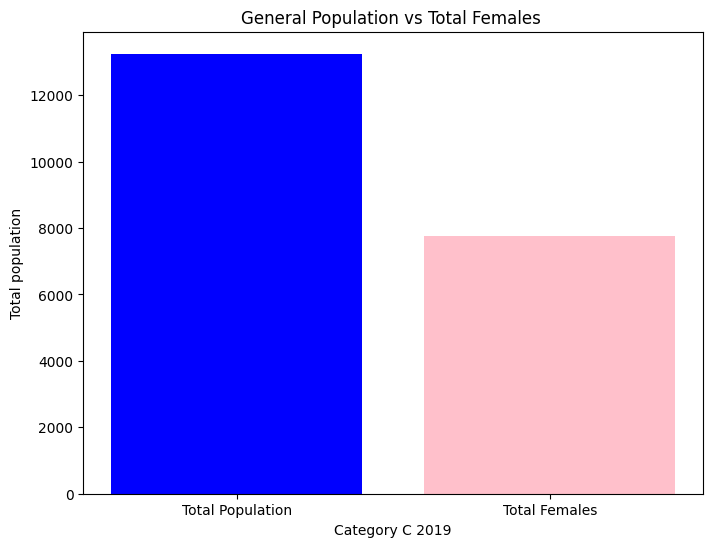

In [ ]:
import matplotlib.pyplot as plt

# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category C 2019")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


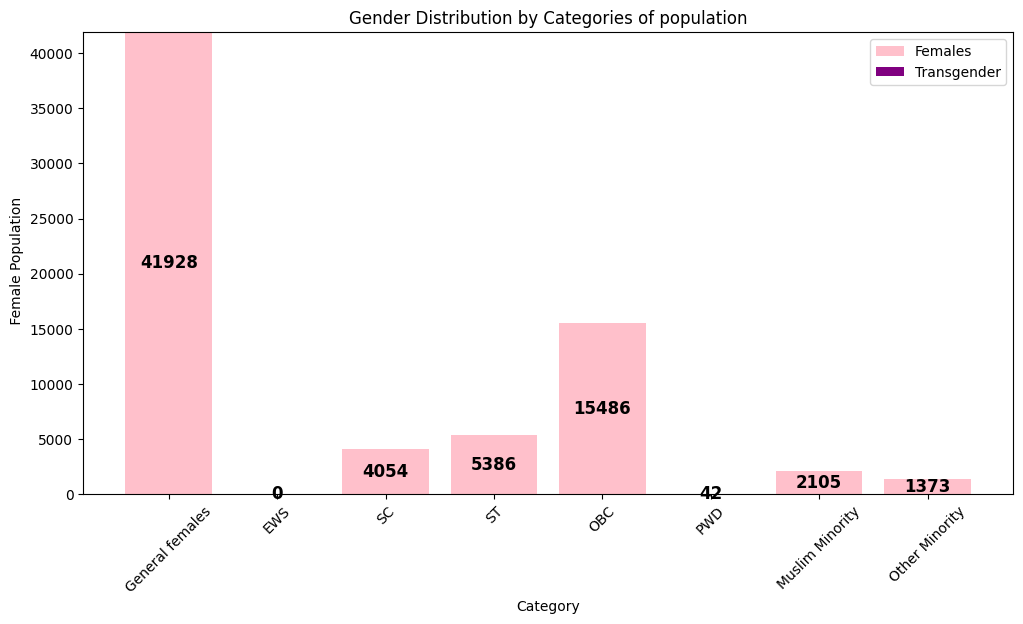

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Define updated female and transgender counts
females = [
    df["total_female"].sum(), df["total_ews_female"].sum(),
    df["total_sc_female"].sum(), df["total_st_female"].sum(),
    df["total_obc_female"].sum(), df["pwd_total_females"].sum(),
    df["muslim_minority_total_females"].sum(), df["other_minority_total_females"].sum()
]

transgenders = [
    df["total_total_transgender"].sum(), df["total_ews_transgender"].sum(),
    df["total_sc_transgender"].sum(), df["total_st_transgender"].sum(),
    df["total_obc_transgender"].sum(), df["pwd_total_transgender"].sum(),
    df["muslim_minority_total_transgender"].sum(), df["other_minority_total_transgender"].sum()
]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories, females, color="pink", label="Females")
bars2 = plt.bar(categories, transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel(" Female Population")
plt.title("Gender Distribution by Categories of population")
plt.legend()
plt.xticks(rotation=45)
plt.show()


<ipython-input-12-cdf519b3e342>:52: RuntimeWarning: invalid value encountered in scalar divide
  percent_female_category = (female_value / category_total) * 100
<ipython-input-12-cdf519b3e342>:53: RuntimeWarning: invalid value encountered in scalar divide
  percent_transgender_category = (transgender_value / category_total) * 100


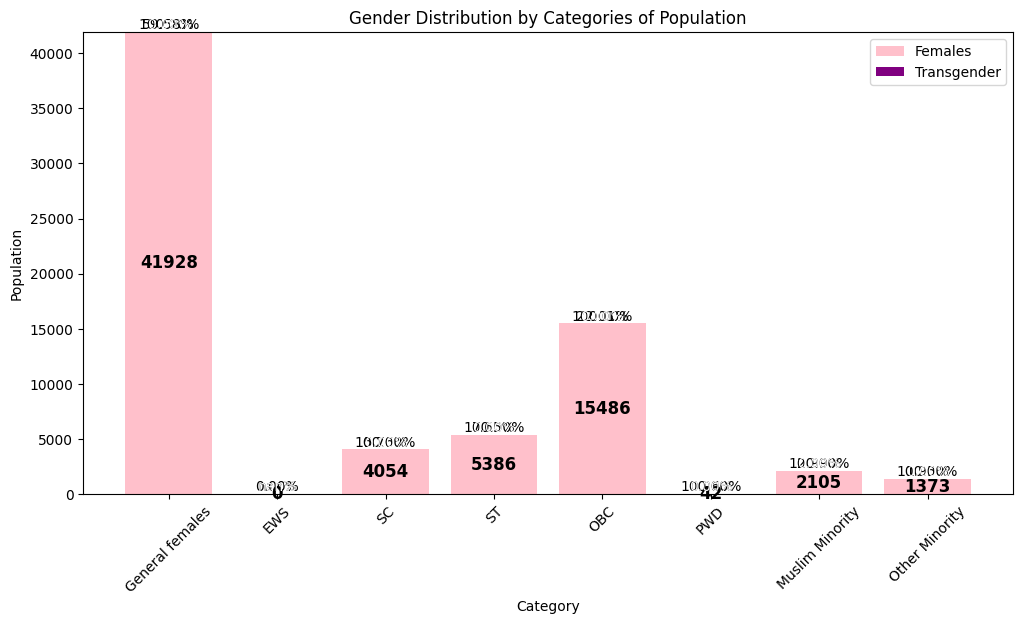

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Define updated female and transgender counts
females = [
    df["total_female"].sum(), df["total_ews_female"].sum(),
    df["total_sc_female"].sum(), df["total_st_female"].sum(),
    df["total_obc_female"].sum(), df["pwd_total_females"].sum(),
    df["muslim_minority_total_females"].sum(), df["other_minority_total_females"].sum()
]

transgenders = [
    df["total_total_transgender"].sum(), df["total_ews_transgender"].sum(),
    df["total_sc_transgender"].sum(), df["total_st_transgender"].sum(),
    df["total_obc_transgender"].sum(), df["pwd_total_transgender"].sum(),
    df["muslim_minority_total_transgender"].sum(), df["other_minority_total_transgender"].sum()
]

# Calculate total population for each category
total_population = [f + t for f, t in zip(females, transgenders)]

# Calculate the total population across all categories
total_population_all = sum(total_population)

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories, females, color="pink", label="Females")
bars2 = plt.bar(categories, transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values and percentages
for bar, value, category_total in zip(bars1, females, total_population):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

    # Calculate and display the percentage of females relative to total population
    percent_female_total = (value / total_population_all) * 100
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f"{percent_female_total:.2f}%", ha='center', va='bottom', fontsize=10, color='black')

for bar, female_value, transgender_value, category_total in zip(bars2, females, transgenders, total_population):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

        # Calculate and display the percentage of transgenders relative to total population
        percent_transgender_total = (transgender_value / total_population_all) * 100
        plt.text(bar.get_x() + bar.get_width()/2, female_value + transgender_value + 0.05, f"{percent_transgender_total:.2f}%", ha='center', va='bottom', fontsize=10, color='white')

    # Calculate and display the percentage of females and transgenders relative to their own category
    percent_female_category = (female_value / category_total) * 100
    percent_transgender_category = (transgender_value / category_total) * 100
    plt.text(bar.get_x() + bar.get_width()/2, female_value + 0.05, f"{percent_female_category:.2f}%", ha='center', va='bottom', fontsize=10, color='black')
    plt.text(bar.get_x() + bar.get_width()/2, female_value + transgender_value + 0.05, f"{percent_transgender_category:.2f}%", ha='center', va='bottom', fontsize=10, color='white')

plt.xlabel("Category")
plt.ylabel("Population")
plt.title("Gender Distribution by Categories of Population")
plt.legend()
plt.xticks(rotation=45)
plt.show()


In [ ]:
# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Define updated female and transgender counts
females = [
    df["total_female"].sum(), df["total_ews_female"].sum(),
    df["total_sc_female"].sum(), df["total_st_female"].sum(),
    df["total_obc_female"].sum(), df["pwd_total_females"].sum(),
    df["muslim_minority_total_females"].sum(), df["other_minority_total_females"].sum()
]

transgenders = [
    df["total_total_transgender"].sum(), df["total_ews_transgender"].sum(),
    df["total_sc_transgender"].sum(), df["total_st_transgender"].sum(),
    df["total_obc_transgender"].sum(), df["pwd_total_transgender"].sum(),
    df["muslim_minority_total_transgender"].sum(), df["other_minority_total_transgender"].sum()
]

# Calculate total population for each category
total_population = [f + t for f, t in zip(females, transgenders)]

# Calculate the total population across all categories
total_population_all = sum(total_population)

# Print the ratios and percentages
print("Percentages of Females and Transgenders Relative to Total Population:")
for category, female, transgender, total in zip(categories, females, transgenders, total_population):
    percent_female_total = (female / total_population_all) * 100
    percent_transgender_total = (transgender / total_population_all) * 100
    print(f"\n{category}:")
    print(f"  - Female: {female} ({percent_female_total:.2f}%) of total population")
    print(f"  - Transgender: {transgender} ({percent_transgender_total:.2f}%) of total population")

print("\nPercentages of Females and Transgenders Relative to Own Category Total:")
for category, female, transgender, total in zip(categories, females, transgenders, total_population):
    percent_female_category = (female / total) * 100
    percent_transgender_category = (transgender / total) * 100
    print(f"\n{category}:")
    print(f"  - Female: {female} ({percent_female_category:.2f}%) of category total")
    print(f"  - Transgender: {transgender} ({percent_transgender_category:.2f}%) of category total")


Percentages of Females and Transgenders Relative to Total Population:

General females:
  - Female: 41928 (59.58%) of total population
  - Transgender: 0 (0.00%) of total population

EWS:
  - Female: 0 (0.00%) of total population
  - Transgender: 0 (0.00%) of total population

SC:
  - Female: 4054 (5.76%) of total population
  - Transgender: 0 (0.00%) of total population

ST:
  - Female: 5386 (7.65%) of total population
  - Transgender: 0 (0.00%) of total population

OBC:
  - Female: 15486 (22.01%) of total population
  - Transgender: 0 (0.00%) of total population

PWD:
  - Female: 42 (0.06%) of total population
  - Transgender: 0 (0.00%) of total population

Muslim Minority:
  - Female: 2105 (2.99%) of total population
  - Transgender: 0 (0.00%) of total population

Other Minority:
  - Female: 1373 (1.95%) of total population
  - Transgender: 0 (0.00%) of total population

Percentages of Females and Transgenders Relative to Own Category Total:

General females:
  - Female: 41928 (100.

<ipython-input-13-148153a32695>:39: RuntimeWarning: invalid value encountered in scalar divide
  percent_female_category = (female / total) * 100
<ipython-input-13-148153a32695>:40: RuntimeWarning: invalid value encountered in scalar divide
  percent_transgender_category = (transgender / total) * 100


In [ ]:
# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for university type

    # Define updated female and transgender counts
    females = [
        df_filtered["total_female"].sum(), df_filtered["total_ews_female"].sum(),
        df_filtered["total_sc_female"].sum(), df_filtered["total_st_female"].sum(),
        df_filtered["total_obc_female"].sum(), df_filtered["pwd_total_females"].sum(),
        df_filtered["muslim_minority_total_females"].sum(), df_filtered["other_minority_total_females"].sum()
    ]

    transgenders = [
        df_filtered["total_total_transgender"].sum(), df_filtered["total_ews_transgender"].sum(),
        df_filtered["total_sc_transgender"].sum(), df_filtered["total_st_transgender"].sum(),
        df_filtered["total_obc_transgender"].sum(), df_filtered["pwd_total_transgender"].sum(),
        df_filtered["muslim_minority_total_transgender"].sum(), df_filtered["other_minority_total_transgender"].sum()
    ]

    # Calculate total population for each category
    total_population = [f + t for f, t in zip(females, transgenders)]

    # Calculate the total population across all categories for this university type
    total_population_all = sum(total_population)

    print(f"\n=== Statistics for {uni_type} ===\n")

    # Print the ratios and percentages
    print("Percentages of Females and Transgenders Relative to Total Population:")
    for category, female, transgender, total in zip(categories, females, transgenders, total_population):
        percent_female_total = (female / total_population_all) * 100 if total_population_all else 0
        percent_transgender_total = (transgender / total_population_all) * 100 if total_population_all else 0
        print(f"\n{category}:")
        print(f"  - Female: {female} ({percent_female_total:.2f}%) of total population")
        print(f"  - Transgender: {transgender} ({percent_transgender_total:.2f}%) of total population")

    print("\nPercentages of Females and Transgenders Relative to Own Category Total:")
    for category, female, transgender, total in zip(categories, females, transgenders, total_population):
        percent_female_category = (female / total) * 100 if total else 0
        percent_transgender_category = (transgender / total) * 100 if total else 0
        print(f"\n{category}:")
        print(f"  - Female: {female} ({percent_female_category:.2f}%) of category total")
        print(f"  - Transgender: {transgender} ({percent_transgender_category:.2f}%) of category total")

    print("\n" + "="*50)  # Separator for clarity



=== Statistics for State Public University  ===

Percentages of Females and Transgenders Relative to Total Population:

General females:
  - Female: 34171 (59.73%) of total population
  - Transgender: 0 (0.00%) of total population

EWS:
  - Female: 0 (0.00%) of total population
  - Transgender: 0 (0.00%) of total population

SC:
  - Female: 3592 (6.28%) of total population
  - Transgender: 0 (0.00%) of total population

ST:
  - Female: 3321 (5.80%) of total population
  - Transgender: 0 (0.00%) of total population

OBC:
  - Female: 13889 (24.28%) of total population
  - Transgender: 0 (0.00%) of total population

PWD:
  - Female: 15 (0.03%) of total population
  - Transgender: 0 (0.00%) of total population

Muslim Minority:
  - Female: 1919 (3.35%) of total population
  - Transgender: 0 (0.00%) of total population

Other Minority:
  - Female: 303 (0.53%) of total population
  - Transgender: 0 (0.00%) of total population

Percentages of Females and Transgenders Relative to Own Category

### 2019 S

Load the dataset

In [ ]:
import pandas as pd
# Define the path to your file in Colab's storage
file_path = '/content/2019/Block-6-Enrollment_detais.csv'  # Update with your actual file name

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

In [ ]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,S-100,2019,S,Gujarat,Ahmadabad,NaN,380058,Rural,PGDM Institutes,NaN,...,1,0,0,19,8,0,0,160,56,0
1,S-100,2019,S,Gujarat,Ahmadabad,NaN,380058,Rural,PGDM Institutes,NaN,...,0,0,0,0,0,0,0,187,87,0
2,S-10000,2019,S,Maharashtra,Solapur,NaN,413216,Urban,Teacher Training,NaN,...,0,0,0,0,0,0,0,31,23,0
3,S-10000,2019,S,Maharashtra,Solapur,NaN,413216,Urban,Teacher Training,NaN,...,0,0,0,0,0,0,0,49,36,0
4,S-10004,2019,S,Maharashtra,Nagpur,NaN,441107,Rural,Teacher Training,NaN,...,0,0,0,0,0,0,0,50,39,0


In [ ]:
# Print all column names
print("All columns in the DataFrame:\n")
print(df.columns.tolist())  # Convert to list for better readability

# Check if 'university_type' exists
if "university_type" in df.columns:
    print("\n✅ 'university_type' column exists in the DataFrame.")
else:
    print("\n❌ 'university_type' column does NOT exist in the DataFrame.")


All columns in the DataFrame:

['aishe_code', 'survey_year', 'institution_category', 'state', 'district', 'block', 'pincode', 'location', 'institute_type', 'ownership_status', 'management', 'year', 'programme', 'discipline', 'level', 'discipline_group_category', 'course_mode_id', 'seats_earmarked_general', 'general_total', 'general_total_female', 'general_total_transgender', 'seats_earmarked_ews', 'total_ews_total', 'total_ews_female', 'total_ews_transgender', 'seats_earmarked_sc', 'total_sc', 'total_sc_female', 'total_sc_transgender', 'seats_earmarked_st', 'total_st', 'total_st_female', 'total_st_transgender', 'seats_earmarked_obc', 'total_obc', 'total_obc_female', 'total_obc_transgender', 'pwd_total', 'pwd_total_females', 'pwd_total_transgender', 'muslim_minority_total', 'muslim_minority_total_females', 'muslim_minority_total_transgender', 'other_minority_total', 'other_minority_total_females', 'other_minority_total_transgender', 'seats_earmarked_total', 'total', 'total_female', 'tot

In [ ]:
total_sum = df['total'].sum()
print(total_sum)

1958970


In [ ]:
# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and compute the total sum
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_sum = df_filtered["total"].sum()  # Compute total sum for this category

    # Print results
    print(f"Total Sum for {uni_type}: {total_sum:,}")

KeyError: 'university_type'

Analysis

UG population filtering

In [ ]:
#Filter the data quickly

# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'level' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'level'
    df['discipline'] = df['discipline'].str.strip()
    df['level'] = df['level'].str.strip()

    # Convert to lowercase for better matching
    df['discipline'] = df['discipline'].str.lower()
    df['level'] = df['level'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("economics", na=False)]

    # Further filter for 'level' matching 'under graduate' or variants
    df_filtered = df_filtered[df_filtered['level'].str.contains(r'under graduate', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 49811
Number of rows after filtering: 3
      aishe_code  survey_year institution_category        state district  \
48369     S-9170         2019                    S  Maharashtra   Raigad   
48385     S-9170         2019                    S  Maharashtra   Raigad   
48400     S-9170         2019                    S  Maharashtra   Raigad   

       block  pincode location    institute_type  ownership_status  ...  \
48369    NaN   410201    Rural  Teacher Training               NaN  ...   
48385    NaN   410201    Rural  Teacher Training               NaN  ...   
48400    NaN   410201    Rural  Teacher Training               NaN  ...   

      muslim_minority_total  muslim_minority_total_females  \
48369                     0                              0   
48385                     0                              0   
48400                     0                              0   

      muslim_minority_total_transgender other_minority_total  \
48369            

In [ ]:
df = df_filtered

Summary Statistics

In [ ]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total"
]

# Ensure all variables exist in the dataset
variables = [var for var in variables if var in df_filtered.columns]

# Summary statistics
summary_stats = df_filtered[variables].describe()

# Print results
print("Summary Statistics for Concerned Variables:\n")
print(summary_stats)

Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count       3.000000              3.000000                        3.0   
mean        2.666667              1.000000                        0.0   
std         3.055050              1.732051                        0.0   
min         0.000000              0.000000                        0.0   
25%         1.000000              0.000000                        0.0   
50%         2.000000              0.000000                        0.0   
75%         4.000000              1.500000                        0.0   
max         6.000000              3.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count               3.0                    3.0              3.0   
mean                0.0                    0.0              0.0   
std                 0.0                    0.0              0.0   
min                 0.0      

In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females): {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


Gender Share in Total Population:

Total Population (UG Economics): 8
Total Females): 3 (37.50%)
Total Transgender Individuals: 0 (0.00%)


In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and calculate gender-related statistics
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_population = df_filtered["total"].sum()
    total_females_excluding_variable = df_filtered["total_female"].sum()
    total_transgender = df_filtered["total_total_transgender"].sum()

    # Compute shares (avoid division by zero)
    female_share = (total_females_excluding_variable / total_population) * 100 if total_population else 0
    transgender_share = (total_transgender / total_population) * 100 if total_population else 0

    # Print results
    print(f"\nGender Share in {uni_type}:\n")
    print(f"Total Population: {total_population:,}")
    print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
    print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


In [ ]:
# Compute total dataset population
total_population = df["total"].sum()

# Compute total for each category
total_ews = df["total_ews_total"].sum()
total_sc = df["total_sc"].sum()
total_st = df["total_st"].sum()
total_obc = df["total_obc"].sum()
total_pwd = df["pwd_total"].sum()
total_muslims = df["muslim_minority_total"].sum()
total_other_minorities = df["other_minority_total"].sum()

# Compute total females for each category (new variables assigned)
total_female_ews = df["total_ews_female"].sum()
total_female_sc = df["total_sc_female"].sum()
total_female_st = df["total_st_female"].sum()
total_female_obc = df["total_obc_female"].sum()
total_female_pwd = df["pwd_total_females"].sum()
total_female_muslims = df["muslim_minority_total_females"].sum()
total_female_other_minorities = df["other_minority_total_females"].sum()

# Compute shares
female_ews_share = (total_female_ews / total_ews) * 100 if total_ews != 0 else 0
female_sc_share = (total_female_sc / total_sc) * 100 if total_sc != 0 else 0
female_st_share = (total_female_st / total_st) * 100 if total_st != 0 else 0
female_obc_share = (total_female_obc / total_obc) * 100 if total_obc != 0 else 0
female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd != 0 else 0
female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims != 0 else 0
female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities != 0 else 0

# Print results
print("\nCategory-wise Population Breakdown:\n")
print(f"Total Dataset Population: {total_population:,}")

print(f"\nTotal EWS (UG Economics): {total_ews:,}")
print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

print(f"\nTotal SC (UG Economics): {total_sc:,}")
print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

print(f"\nTotal ST (UG Economics): {total_st:,}")
print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

print(f"\nTotal OBC (UG Economics): {total_obc:,}")
print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")



Category-wise Population Breakdown:

Total Dataset Population: 8

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 0
Total Female SC: 0 (0.00%)

Total ST (UG Economics): 0
Total Female ST: 0 (0.00%)

Total OBC (UG Economics): 0
Total Female OBC: 0 (0.00%)

Total PWD (UG Economics): 0
Total Female PWD: 0 (0.00%)

Total Muslims (UG Economics): 0
Total Female Muslim Minority: 0 (0.00%)

Total Other Minorities (UG Economics): 0
Total Female Other Minority: 0 (0.00%)


In [ ]:
# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for university type

    # Compute total dataset population for this university type
    total_population = df_filtered["total"].sum()

    # Compute total for each category
    total_ews = df_filtered["total_ews_total"].sum()
    total_sc = df_filtered["total_sc"].sum()
    total_st = df_filtered["total_st"].sum()
    total_obc = df_filtered["total_obc"].sum()
    total_pwd = df_filtered["pwd_total"].sum()
    total_muslims = df_filtered["muslim_minority_total"].sum()
    total_other_minorities = df_filtered["other_minority_total"].sum()

    # Compute total females for each category
    total_female_ews = df_filtered["total_ews_female"].sum()
    total_female_sc = df_filtered["total_sc_female"].sum()
    total_female_st = df_filtered["total_st_female"].sum()
    total_female_obc = df_filtered["total_obc_female"].sum()
    total_female_pwd = df_filtered["pwd_total_females"].sum()
    total_female_muslims = df_filtered["muslim_minority_total_females"].sum()
    total_female_other_minorities = df_filtered["other_minority_total_females"].sum()

    # Compute shares
    female_ews_share = (total_female_ews / total_ews) * 100 if total_ews else 0
    female_sc_share = (total_female_sc / total_sc) * 100 if total_sc else 0
    female_st_share = (total_female_st / total_st) * 100 if total_st else 0
    female_obc_share = (total_female_obc / total_obc) * 100 if total_obc else 0
    female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd else 0
    female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims else 0
    female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities else 0

    # Print results
    print(f"\n=== Statistics for {uni_type} ===\n")
    print(f"Total Dataset Population: {total_population:,}")

    print(f"\nTotal EWS (UG Economics): {total_ews:,}")
    print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

    print(f"\nTotal SC (UG Economics): {total_sc:,}")
    print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

    print(f"\nTotal ST (UG Economics): {total_st:,}")
    print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

    print(f"\nTotal OBC (UG Economics): {total_obc:,}")
    print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

    print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
    print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

    print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
    print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

    print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
    print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")

    print("\n" + "="*50)  # Separator for clarity


Results

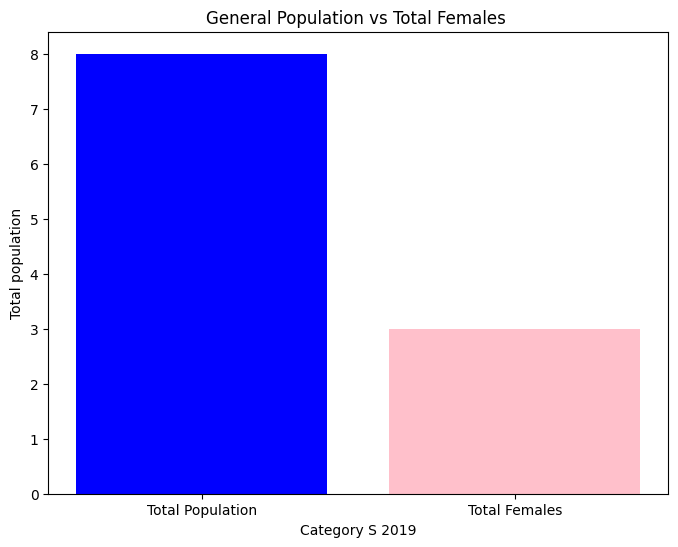

In [ ]:
# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category S 2019")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


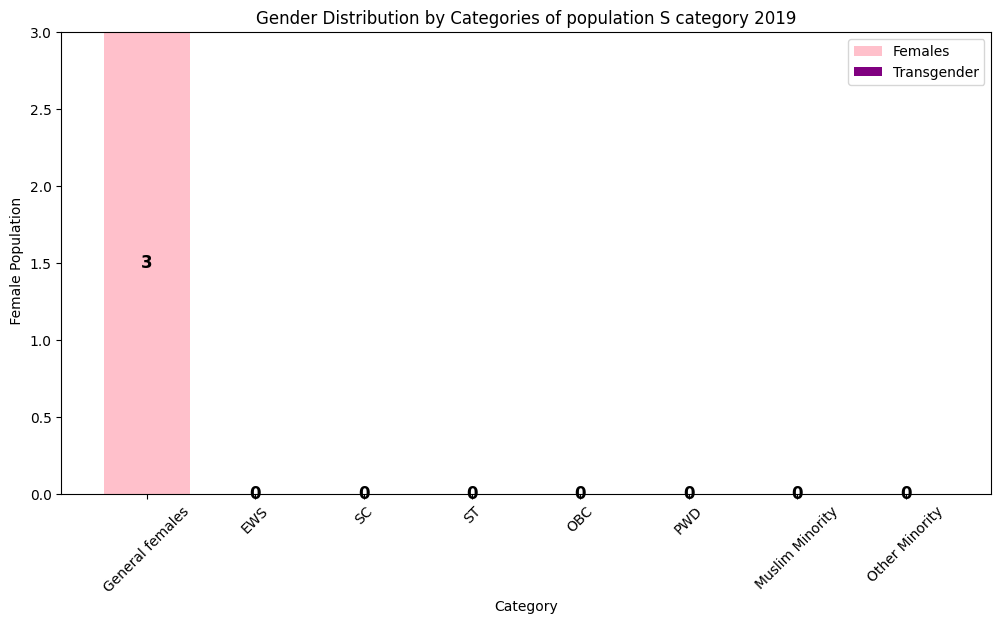

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Define updated female and transgender counts
females = [
    df["total_female"].sum(), df["total_ews_female"].sum(),
    df["total_sc_female"].sum(), df["total_st_female"].sum(),
    df["total_obc_female"].sum(), df["pwd_total_females"].sum(),
    df["muslim_minority_total_females"].sum(), df["other_minority_total_females"].sum()
]

transgenders = [
    df["total_total_transgender"].sum(), df["total_ews_transgender"].sum(),
    df["total_sc_transgender"].sum(), df["total_st_transgender"].sum(),
    df["total_obc_transgender"].sum(), df["pwd_total_transgender"].sum(),
    df["muslim_minority_total_transgender"].sum(), df["other_minority_total_transgender"].sum()
]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories, females, color="pink", label="Females")
bars2 = plt.bar(categories, transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel(" Female Population")
plt.title("Gender Distribution by Categories of population S category 2019")
plt.legend()
plt.xticks(rotation=45)
plt.show()


### 2019 U

Load the dataset

In [ ]:
import pandas as pd
# Define the path to your file in Colab's storage
file_path = '/content/2019/Block 6 - Category wise student enrollment.csv'  # Update with your actual file name

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

In [ ]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,U-0001,2019,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,1,0,0,0,0,0,0,53,30,0
1,U-0001,2019,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,0,0,0,0,0,0,0,0,0,0
2,U-0001,2019,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,9,7,0,0,0,0,0,179,89,0
3,U-0001,2019,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,0,0,0,0,0,0,0,38,24,0
4,U-0001,2019,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,2,1,0,0,0,0,0,41,29,0


In [ ]:
# Print all column names
print("All columns in the DataFrame:\n")
print(df.columns.tolist())  # Convert to list for better readability

# Check if 'university_type' exists
if "university_type" in df.columns:
    print("\n✅ 'university_type' column exists in the DataFrame.")
else:
    print("\n❌ 'university_type' column does NOT exist in the DataFrame.")


All columns in the DataFrame:

['aishe_code', 'survey_year', 'institution_category', 'state', 'district', 'block', 'pincode', 'location', 'institute_type', 'ownership_status', 'management', 'year', 'programme', 'discipline', 'level', 'discipline_group_category', 'course_mode_id', 'seats_earmarked_general', 'general_total', 'general_total_female', 'general_total_transgender', 'seats_earmarked_ews', 'total_ews_total', 'total_ews_female', 'total_ews_transgender', 'seats_earmarked_sc', 'total_sc', 'total_sc_female', 'total_sc_transgender', 'seats_earmarked_st', 'total_st', 'total_st_female', 'total_st_transgender', 'seats_earmarked_obc', 'total_obc', 'total_obc_female', 'total_obc_transgender', 'pwd_total', 'pwd_total_females', 'pwd_total_transgender', 'muslim_minority_total', 'muslim_minority_total_females', 'muslim_minority_total_transgender', 'other_minority_total', 'other_minority_total_females', 'other_minority_total_transgender', 'seats_earmarked_total', 'total', 'total_female', 'tot

Analysis

In [ ]:
total_sum = df['total'].sum()
print(total_sum)

7590244


In [ ]:
# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and compute the total sum
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_sum = df_filtered["total"].sum()  # Compute total sum for this category

    # Print results
    print(f"Total Sum for {uni_type}: {total_sum:,}")

UG population filtering

In [ ]:
# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'programme' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'programme'
    df['discipline'] = df['discipline'].str.strip()
    df['programme'] = df['programme'].str.strip()

    # Convert to lowercase for better matching
    df['discipline'] = df['discipline'].str.lower()
    df['programme'] = df['programme'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("economics", na=False)]

    # Further filter for 'programme' matching 'B.A.(Hons)-Bachelor of Arts (Honors)' or variants
    df_filtered = df_filtered[df_filtered['programme'].str.contains(r'\bb\.a', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 77393
Number of rows after filtering: 188
     aishe_code  survey_year institution_category           state   district  \
2368     U-0035         2019                    U  Andhra Pradesh  Anantapur   
2405     U-0035         2019                    U  Andhra Pradesh  Anantapur   
2421     U-0035         2019                    U  Andhra Pradesh  Anantapur   
3376     U-0049         2019                    U           Assam     Kamrup   
3417     U-0049         2019                    U           Assam     Kamrup   

      block  pincode location              institute_type  ownership_status  \
2368    NaN   515134    Urban  Deemed University-Private                NaN   
2405    NaN   515134    Urban  Deemed University-Private                NaN   
2421    NaN   515134    Urban  Deemed University-Private                NaN   
3376    NaN   782402    Urban   State Private University                NaN   
3417    NaN   782402    Urban   State Private University  

In [ ]:
df = df_filtered

Summary Statistics

In [ ]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total"
]

# Ensure all variables exist in the dataset
variables = [var for var in variables if var in df_filtered.columns]

# Summary statistics
summary_stats = df_filtered[variables].describe()

# Print results
print("Summary Statistics for Concerned Variables:\n")
print(summary_stats)

Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count     188.000000            188.000000                      188.0   
mean       16.670213              8.324468                        0.0   
std        27.912157             13.695545                        0.0   
min         0.000000              0.000000                        0.0   
25%         0.000000              0.000000                        0.0   
50%         6.000000              3.000000                        0.0   
75%        20.000000             10.000000                        0.0   
max       150.000000             80.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count             188.0                  188.0       188.000000   
mean                0.0                    0.0         0.893617   
std                 0.0                    0.0         1.986414   
min                 0.0      

In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females): {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


Gender Share in Total Population:

Total Population (UG Economics): 4,904
Total Females): 2,333 (47.57%)
Total Transgender Individuals: 0 (0.00%)


In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and calculate gender-related statistics
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_population = df_filtered["total"].sum()
    total_females_excluding_variable = df_filtered["total_female"].sum()
    total_transgender = df_filtered["total_total_transgender"].sum()

    # Compute shares (avoid division by zero)
    female_share = (total_females_excluding_variable / total_population) * 100 if total_population else 0
    transgender_share = (total_transgender / total_population) * 100 if total_population else 0

    # Print results
    print(f"\nGender Share in {uni_type}:\n")
    print(f"Total Population: {total_population:,}")
    print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
    print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


In [ ]:
# Compute total dataset population
total_population = df["total"].sum()

# Compute total for each category
total_ews = df["total_ews_total"].sum()
total_sc = df["total_sc"].sum()
total_st = df["total_st"].sum()
total_obc = df["total_obc"].sum()
total_pwd = df["pwd_total"].sum()
total_muslims = df["muslim_minority_total"].sum()
total_other_minorities = df["other_minority_total"].sum()

# Compute total females for each category (new variables assigned)
total_female_ews = df["total_ews_female"].sum()
total_female_sc = df["total_sc_female"].sum()
total_female_st = df["total_st_female"].sum()
total_female_obc = df["total_obc_female"].sum()
total_female_pwd = df["pwd_total_females"].sum()
total_female_muslims = df["muslim_minority_total_females"].sum()
total_female_other_minorities = df["other_minority_total_females"].sum()

# Compute shares
female_ews_share = (total_female_ews / total_ews) * 100 if total_ews != 0 else 0
female_sc_share = (total_female_sc / total_sc) * 100 if total_sc != 0 else 0
female_st_share = (total_female_st / total_st) * 100 if total_st != 0 else 0
female_obc_share = (total_female_obc / total_obc) * 100 if total_obc != 0 else 0
female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd != 0 else 0
female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims != 0 else 0
female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities != 0 else 0

# Print results
print("\nCategory-wise Population Breakdown:\n")
print(f"Total Dataset Population: {total_population:,}")

print(f"\nTotal EWS (UG Economics): {total_ews:,}")
print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

print(f"\nTotal SC (UG Economics): {total_sc:,}")
print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

print(f"\nTotal ST (UG Economics): {total_st:,}")
print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

print(f"\nTotal OBC (UG Economics): {total_obc:,}")
print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")



Category-wise Population Breakdown:

Total Dataset Population: 4,904

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 392
Total Female SC: 168 (42.86%)

Total ST (UG Economics): 473
Total Female ST: 229 (48.41%)

Total OBC (UG Economics): 873
Total Female OBC: 358 (41.01%)

Total PWD (UG Economics): 13
Total Female PWD: 5 (38.46%)

Total Muslims (UG Economics): 224
Total Female Muslim Minority: 97 (43.30%)

Total Other Minorities (UG Economics): 261
Total Female Other Minority: 142 (54.41%)


In [ ]:
# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for university type

    # Define updated female and transgender counts
    females = [
        df_filtered["total_female"].sum(), df_filtered["total_ews_female"].sum(),
        df_filtered["total_sc_female"].sum(), df_filtered["total_st_female"].sum(),
        df_filtered["total_obc_female"].sum(), df_filtered["pwd_total_females"].sum(),
        df_filtered["muslim_minority_total_females"].sum(), df_filtered["other_minority_total_females"].sum()
    ]

    transgenders = [
        df_filtered["total_total_transgender"].sum(), df_filtered["total_ews_transgender"].sum(),
        df_filtered["total_sc_transgender"].sum(), df_filtered["total_st_transgender"].sum(),
        df_filtered["total_obc_transgender"].sum(), df_filtered["pwd_total_transgender"].sum(),
        df_filtered["muslim_minority_total_transgender"].sum(), df_filtered["other_minority_total_transgender"].sum()
    ]

    # Calculate total population for each category
    total_population = [f + t for f, t in zip(females, transgenders)]

    # Calculate the total population across all categories for this university type
    total_population_all = sum(total_population)

    print(f"\n=== Statistics for {uni_type} ===\n")

    # Print the ratios and percentages
    print("Percentages of Females and Transgenders Relative to Total Population:")
    for category, female, transgender, total in zip(categories, females, transgenders, total_population):
        percent_female_total = (female / total_population_all) * 100 if total_population_all else 0
        percent_transgender_total = (transgender / total_population_all) * 100 if total_population_all else 0
        print(f"\n{category}:")
        print(f"  - Female: {female} ({percent_female_total:.2f}%) of total population")
        print(f"  - Transgender: {transgender} ({percent_transgender_total:.2f}%) of total population")

    print("\nPercentages of Females and Transgenders Relative to Own Category Total:")
    for category, female, transgender, total in zip(categories, females, transgenders, total_population):
        percent_female_category = (female / total) * 100 if total else 0
        percent_transgender_category = (transgender / total) * 100 if total else 0
        print(f"\n{category}:")
        print(f"  - Female: {female} ({percent_female_category:.2f}%) of category total")
        print(f"  - Transgender: {transgender} ({percent_transgender_category:.2f}%) of category total")

    print("\n" + "="*50)  # Separator for clarity


Results

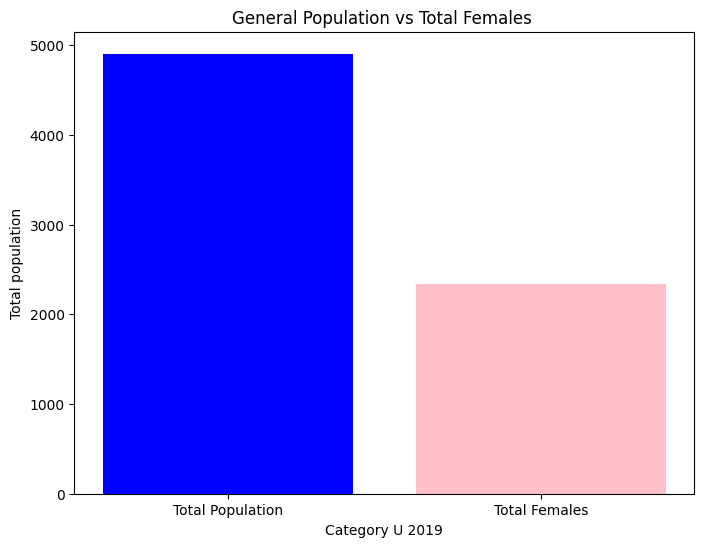

In [ ]:
# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category U 2019")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


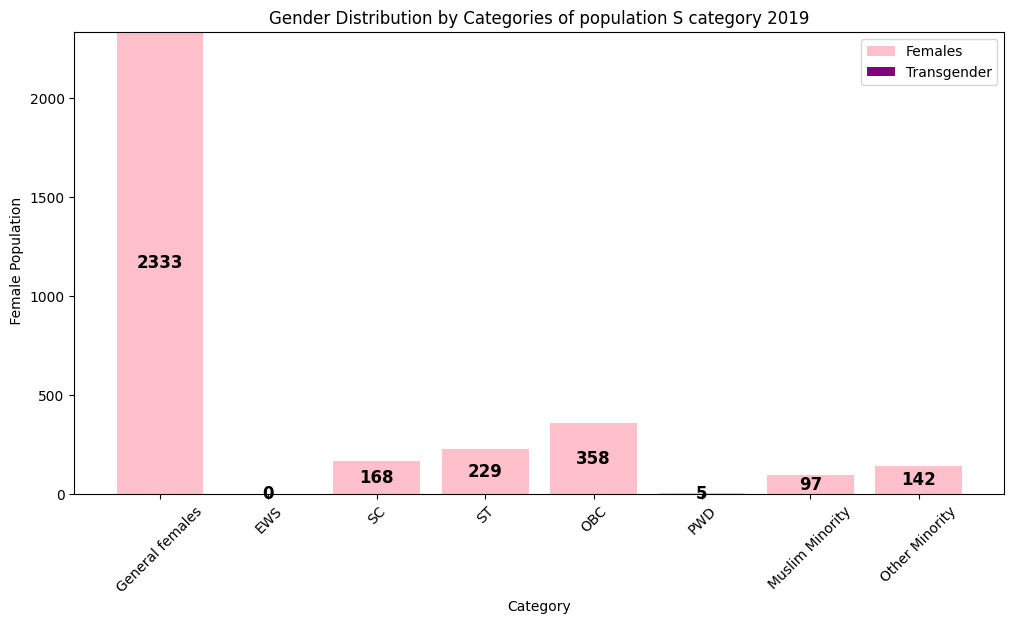

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Define updated female and transgender counts
females = [
    df["total_female"].sum(), df["total_ews_female"].sum(),
    df["total_sc_female"].sum(), df["total_st_female"].sum(),
    df["total_obc_female"].sum(), df["pwd_total_females"].sum(),
    df["muslim_minority_total_females"].sum(), df["other_minority_total_females"].sum()
]

transgenders = [
    df["total_total_transgender"].sum(), df["total_ews_transgender"].sum(),
    df["total_sc_transgender"].sum(), df["total_st_transgender"].sum(),
    df["total_obc_transgender"].sum(), df["pwd_total_transgender"].sum(),
    df["muslim_minority_total_transgender"].sum(), df["other_minority_total_transgender"].sum()
]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories, females, color="pink", label="Females")
bars2 = plt.bar(categories, transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel(" Female Population")
plt.title("Gender Distribution by Categories of population S category 2019")
plt.legend()
plt.xticks(rotation=45)
plt.show()


## 2018

### 2018 C

Load the dataset

In [ ]:
# Define the path to your file in Colab's storage
file_path = '/content/2018/Block-6-all-enrollment.csv'  # Update with your actual file name

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

<ipython-input-70-7a94cc5e04ab>:5: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [ ]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
1,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
2,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
3,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
4,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,236,136,0


In [ ]:
# Check the unique values for the specified columns
institute_type_unique = df['institute_type'].unique()
management_unique = df['management'].unique()
university_type_unique = df['university_type'].unique()

# Printing the unique values
print("Unique values in 'institute_type':", institute_type_unique)
print("Unique values in 'management':", management_unique)
print("Unique values in 'university_type':", university_type_unique)


Unique values in 'institute_type': ['Affiliated College' 'Constituent / University College'
 'PG Center / Off-Campus Center' 'Recognized Center']
Unique values in 'management': ['Private Aided' 'Private Un-Aided' 'State Government' 'Local Body'
 'University' 'Central Government']
Unique values in 'university_type': ['State Public University ' 'State Private University '
 'Deemed University-Private ' 'Central University '
 'Deemed University-Government ' 'Deemed University-Government Aided '
 'Institute under State Legislature Act '
 'Institute of National Importance ']


In [ ]:
# Print all column names
print("All columns in the DataFrame:\n")
print(df.columns.tolist())  # Convert to list for better readability

# Check if 'university_type' exists
if "university_type" in df.columns:
    print("\n✅ 'university_type' column exists in the DataFrame.")
else:
    print("\n❌ 'university_type' column does NOT exist in the DataFrame.")


All columns in the DataFrame:

['aishe_code', 'survey_year', 'institution_category', 'state', 'district', 'block', 'pincode', 'location', 'institute_type', 'ownership_status', 'management', 'university_type', 'year', 'programme', 'discipline', 'level', 'discipline_group_category', 'course_mode_id', 'seats_earmarked_general', 'general_total', 'general_total_female', 'general_total_transgender', 'seats_earmarked_ews', 'total_ews_total', 'total_ews_female', 'total_ews_transgender', 'seats_earmarked_sc', 'total_sc', 'total_sc_female', 'total_sc_transgender', 'seats_earmarked_st', 'total_st', 'total_st_female', 'total_st_transgender', 'seats_earmarked_obc', 'total_obc', 'total_obc_female', 'total_obc_transgender', 'pwd_total', 'pwd_total_females', 'pwd_total_transgender', 'muslim_minority_total', 'muslim_minority_total_females', 'muslim_minority_total_transgender', 'other_minority_total', 'other_minority_total_females', 'other_minority_total_transgender', 'seats_earmarked_total', 'total', '

Analysis

In [ ]:
total_sum = df['total'].sum()
print(total_sum)

26044601


In [ ]:
# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and compute the total sum
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_sum = df_filtered["total"].sum()  # Compute total sum for this category

    # Print results
    print(f"Total Sum for {uni_type}: {total_sum:,}")


Total Sum for State Public University : 25,044,627
Total Sum for State Private University : 84,091
Total Sum for Deemed University-Private : 146,213
Total Sum for Central University : 750,302
Total Sum for Deemed University-Government : 5,787
Total Sum for Deemed University-Government Aided : 2,075
Total Sum for Institute under State Legislature Act : 1,866
Total Sum for Institute of National Importance : 9,640


UG population filtering

In [ ]:
# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'programme' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'programme'
    df['discipline'] = df['discipline'].str.strip()
    df['programme'] = df['programme'].str.strip()

    # Convert to lowercase for better matching
    df['discipline'] = df['discipline'].str.lower()
    df['programme'] = df['programme'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("economics", na=False)]

    # Further filter for 'programme' matching 'B.A.(Hons)-Bachelor of Arts (Honors)' or variants
    df_filtered = df_filtered[df_filtered['programme'].str.contains(r'\bb\.a', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 400488
Number of rows after filtering: 2596
     aishe_code  survey_year institution_category    state     district  \
5526    C-10639         2018                    C  Haryana  Yamunanagar   
5540    C-10639         2018                    C  Haryana  Yamunanagar   
5555    C-10639         2018                    C  Haryana  Yamunanagar   
5569    C-10642         2018                    C  Haryana      Panipat   
5582    C-10642         2018                    C  Haryana      Panipat   

      block pincode location      institute_type  ownership_status  ...  \
5526    NaN  135001    Urban  Affiliated College               NaN  ...   
5540    NaN  135001    Urban  Affiliated College               NaN  ...   
5555    NaN  135001    Urban  Affiliated College               NaN  ...   
5569    NaN  132103    Urban  Affiliated College               NaN  ...   
5582    NaN  132103    Urban  Affiliated College               NaN  ...   

     muslim_minority_total mus

In [ ]:
df = df_filtered

Summary Statistics

In [ ]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total"
]

# Check which variables exist in the dataframe
existing_vars = [var for var in variables if var in df_filtered.columns]
missing_vars = [var for var in variables if var not in df_filtered.columns]

# Print missing variables
if missing_vars:
    print("The following variables are missing from the DataFrame and will not be included in the summary statistics:\n")
    print(missing_vars)
else:
    print("All variables are present in the DataFrame.")

# Use only the existing variables for summary statistics
summary_stats = df_filtered[existing_vars].describe()

# Print results
print("\nSummary Statistics for Concerned Variables:\n")
print(summary_stats)


All variables are present in the DataFrame.

Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count    2596.000000           2596.000000                     2596.0   
mean       11.067797              5.614792                        0.0   
std        17.450509              9.753272                        0.0   
min         0.000000              0.000000                        0.0   
25%         0.000000              0.000000                        0.0   
50%         4.000000              2.000000                        0.0   
75%        14.000000              6.000000                        0.0   
max       265.000000             92.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count            2596.0                 2596.0      2596.000000   
mean                0.0                    0.0         1.520031   
std                 0.0                    0.0     

In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


Gender Share in Total Population:

Total Population (UG Economics): 85,617
Total Females: 38,305 (44.74%)
Total Transgender Individuals: 0 (0.00%)


In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type and calculate gender-related statistics
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for the university type

    total_population = df_filtered["total"].sum()
    total_females_excluding_variable = df_filtered["total_female"].sum()
    total_transgender = df_filtered["total_total_transgender"].sum()

    # Compute shares (avoid division by zero)
    female_share = (total_females_excluding_variable / total_population) * 100 if total_population else 0
    transgender_share = (total_transgender / total_population) * 100 if total_population else 0

    # Print results
    print(f"\nGender Share in {uni_type}:\n")
    print(f"Total Population: {total_population:,}")
    print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
    print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")



Gender Share in State Public University :

Total Population: 72,744
Total Females: 31,121 (42.78%)
Total Transgender Individuals: 0 (0.00%)

Gender Share in Central University :

Total Population: 12,850
Total Females: 7,165 (55.76%)
Total Transgender Individuals: 0 (0.00%)

Gender Share in State Private University :

Total Population: 23
Total Females: 19 (82.61%)
Total Transgender Individuals: 0 (0.00%)


In [ ]:
# Compute total dataset population
total_population = df["total"].sum()

# Compute total for each category
total_ews = df["total_ews_total"].sum()
total_sc = df["total_sc"].sum()
total_st = df["total_st"].sum()
total_obc = df["total_obc"].sum()
total_pwd = df["pwd_total"].sum()
total_muslims = df["muslim_minority_total"].sum()
total_other_minorities = df["other_minority_total"].sum()

# Compute total females for each category (new variables assigned)
total_female_ews = df["total_ews_female"].sum()
total_female_sc = df["total_sc_female"].sum()
total_female_st = df["total_st_female"].sum()
total_female_obc = df["total_obc_female"].sum()
total_female_pwd = df["pwd_total_females"].sum()
total_female_muslims = df["muslim_minority_total_females"].sum()
total_female_other_minorities = df["other_minority_total_females"].sum()

# Compute shares
female_ews_share = (total_female_ews / total_ews) * 100 if total_ews != 0 else 0
female_sc_share = (total_female_sc / total_sc) * 100 if total_sc != 0 else 0
female_st_share = (total_female_st / total_st) * 100 if total_st != 0 else 0
female_obc_share = (total_female_obc / total_obc) * 100 if total_obc != 0 else 0
female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd != 0 else 0
female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims != 0 else 0
female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities != 0 else 0

# Print results
print("\nCategory-wise Population Breakdown:\n")
print(f"Total Dataset Population: {total_population:,}")

print(f"\nTotal EWS (UG Economics): {total_ews:,}")
print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

print(f"\nTotal SC (UG Economics): {total_sc:,}")
print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

print(f"\nTotal ST (UG Economics): {total_st:,}")
print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

print(f"\nTotal OBC (UG Economics): {total_obc:,}")
print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")


Category-wise Population Breakdown:

Total Dataset Population: 85,617

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 9,233
Total Female SC: 3,946 (42.74%)

Total ST (UG Economics): 11,611
Total Female ST: 5,268 (45.37%)

Total OBC (UG Economics): 32,909
Total Female OBC: 13,418 (40.77%)

Total PWD (UG Economics): 75
Total Female PWD: 24 (32.00%)

Total Muslims (UG Economics): 4,513
Total Female Muslim Minority: 1,973 (43.72%)

Total Other Minorities (UG Economics): 2,580
Total Female Other Minority: 1,325 (51.36%)


In [ ]:
# Get unique university types
university_types = df["university_type"].unique()

# Loop through each university type
for uni_type in university_types:
    df_filtered = df[df["university_type"] == uni_type]  # Filter data for university type

    # Compute total dataset population for this university type
    total_population = df_filtered["total"].sum()

    # Compute total for each category
    total_ews = df_filtered["total_ews_total"].sum()
    total_sc = df_filtered["total_sc"].sum()
    total_st = df_filtered["total_st"].sum()
    total_obc = df_filtered["total_obc"].sum()
    total_pwd = df_filtered["pwd_total"].sum()
    total_muslims = df_filtered["muslim_minority_total"].sum()
    total_other_minorities = df_filtered["other_minority_total"].sum()

    # Compute total females for each category
    total_female_ews = df_filtered["total_ews_female"].sum()
    total_female_sc = df_filtered["total_sc_female"].sum()
    total_female_st = df_filtered["total_st_female"].sum()
    total_female_obc = df_filtered["total_obc_female"].sum()
    total_female_pwd = df_filtered["pwd_total_females"].sum()
    total_female_muslims = df_filtered["muslim_minority_total_females"].sum()
    total_female_other_minorities = df_filtered["other_minority_total_females"].sum()

    # Compute shares
    female_ews_share = (total_female_ews / total_ews) * 100 if total_ews else 0
    female_sc_share = (total_female_sc / total_sc) * 100 if total_sc else 0
    female_st_share = (total_female_st / total_st) * 100 if total_st else 0
    female_obc_share = (total_female_obc / total_obc) * 100 if total_obc else 0
    female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd else 0
    female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims else 0
    female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities else 0

    # Print results
    print(f"\n=== Statistics for {uni_type} ===\n")
    print(f"Total Dataset Population: {total_population:,}")

    print(f"\nTotal EWS (UG Economics): {total_ews:,}")
    print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

    print(f"\nTotal SC (UG Economics): {total_sc:,}")
    print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

    print(f"\nTotal ST (UG Economics): {total_st:,}")
    print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

    print(f"\nTotal OBC (UG Economics): {total_obc:,}")
    print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

    print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
    print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

    print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
    print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

    print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
    print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")

    print("\n" + "="*50)  # Separator for clarity



=== Statistics for State Public University  ===

Total Dataset Population: 72,744

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 8,352
Total Female SC: 3,487 (41.75%)

Total ST (UG Economics): 7,158
Total Female ST: 3,234 (45.18%)

Total OBC (UG Economics): 30,747
Total Female OBC: 12,203 (39.69%)

Total PWD (UG Economics): 46
Total Female PWD: 12 (26.09%)

Total Muslims (UG Economics): 4,291
Total Female Muslim Minority: 1,829 (42.62%)

Total Other Minorities (UG Economics): 562
Total Female Other Minority: 302 (53.74%)


=== Statistics for Central University  ===

Total Dataset Population: 12,850

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 881
Total Female SC: 459 (52.10%)

Total ST (UG Economics): 4,444
Total Female ST: 2,026 (45.59%)

Total OBC (UG Economics): 2,158
Total Female OBC: 1,212 (56.16%)

Total PWD (UG Economics): 29
Total Female PWD: 12 (41.38%)

Total Muslims (UG Economics): 222
Total Female Mu

Results

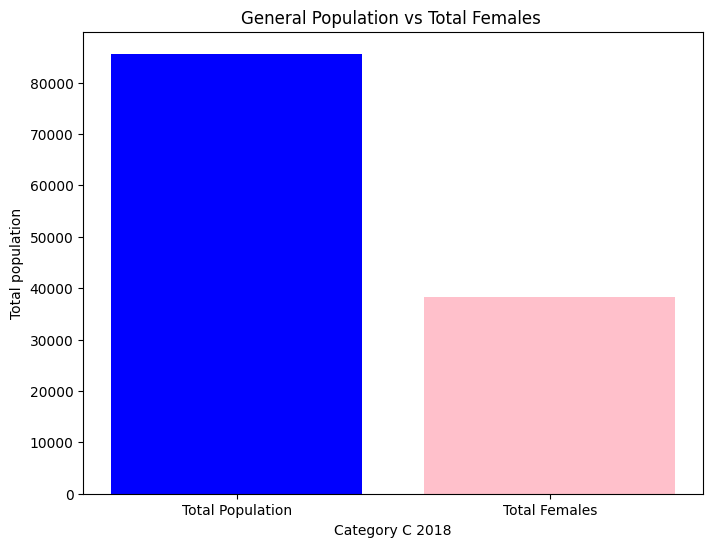

In [ ]:
# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category C 2018")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


All categories are present in the DataFrame.


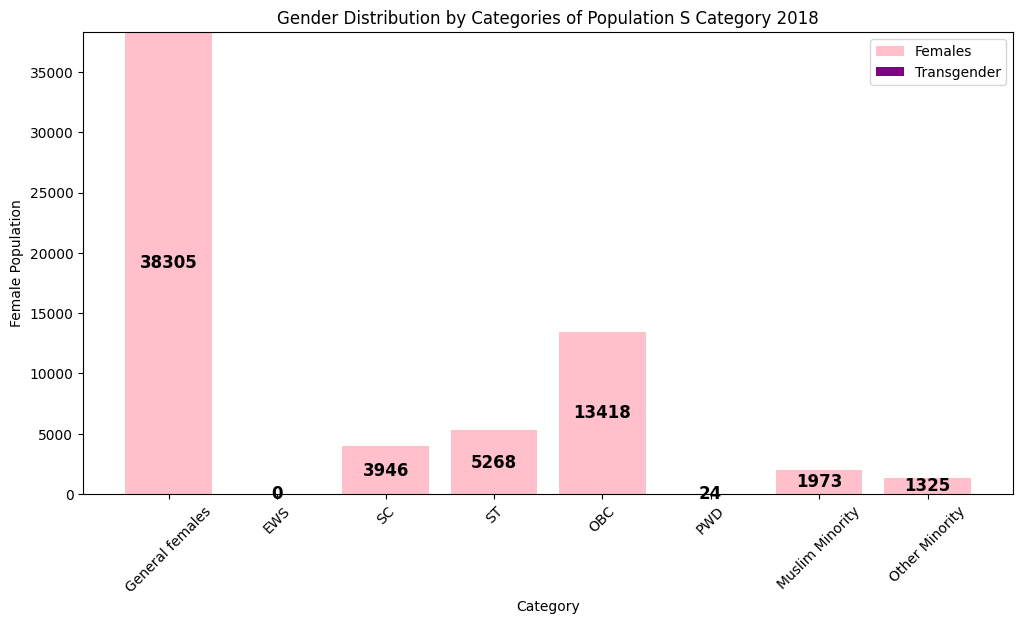

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Corresponding variables for females and transgenders
female_columns = [
    "total_female", "total_ews_female", "total_sc_female", "total_st_female",
    "total_obc_female", "pwd_total_females", "muslim_minority_total_females", "other_minority_total_females"
]

transgender_columns = [
    "total_total_transgender", "total_ews_transgender", "total_sc_transgender", "total_st_transgender",
    "total_obc_transgender", "pwd_total_transgender", "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Check if all the columns exist in df
existing_females = [col for col in female_columns if col in df.columns]
existing_transgenders = [col for col in transgender_columns if col in df.columns]

# Identify missing columns
missing_females = [col for col in female_columns if col not in df.columns]
missing_transgenders = [col for col in transgender_columns if col not in df.columns]

# Print missing categories if any
if missing_females or missing_transgenders:
    print("The following categories are missing from the DataFrame and will not be included in the plot:")
    if missing_females:
        print("Missing female category columns:", missing_females)
    if missing_transgenders:
        print("Missing transgender category columns:", missing_transgenders)
else:
    print("All categories are present in the DataFrame.")

# Define the female and transgender counts using only existing columns
females = [df[col].sum() for col in existing_females]
transgenders = [df[col].sum() for col in existing_transgenders]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories[:len(females)], females, color="pink", label="Females")
bars2 = plt.bar(categories[:len(transgenders)], transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel("Female Population")
plt.title("Gender Distribution by Categories of Population S Category 2018")
plt.legend()
plt.xticks(rotation=45)
plt.show()


### 2018 s

Load the dataset

In [ ]:
# Define the path to your file in Colab's storage
file_path = '/content/2018/Block-6-enrollment_details_S.csv'  # Update with your actual file name

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

In [ ]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,S-100,2018,S,Gujarat,Ahmadabad,NaN,380058,Rural,PGDM Institutes,NaN,...,1,0,0,19,8,0,0,160,56,0
1,S-100,2018,S,Gujarat,Ahmadabad,NaN,380058,Rural,PGDM Institutes,NaN,...,7,4,0,0,0,0,0,106,50,0
2,S-10000,2018,S,Maharashtra,Solapur,NaN,413216,Urban,Teacher Training,NaN,...,0,0,0,0,0,0,0,35,23,0
3,S-10000,2018,S,Maharashtra,Solapur,NaN,413216,Urban,Teacher Training,NaN,...,0,0,0,0,0,0,0,58,47,0
4,S-10003,2018,S,Maharashtra,Gadchiroli,NaN,441208,Rural,Teacher Training,NaN,...,0,0,0,0,0,0,0,0,0,0


Analysis

In [ ]:
total_sum = df['total'].sum()
print(total_sum)

2023185


UG population filtering

In [ ]:
# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'programme' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'programme'
    df['discipline'] = df['discipline'].str.strip()
    df['programme'] = df['programme'].str.strip()

    # Convert to lowercase for better matching
    df['discipline'] = df['discipline'].str.lower()
    df['programme'] = df['programme'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("economics", na=False)]

    # Further filter for 'programme' matching 'B.A.(Hons)-Bachelor of Arts (Honors)' or variants
    df_filtered = df_filtered[df_filtered['programme'].str.contains(r'\bb\.a', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 48633
Number of rows after filtering: 3
      aishe_code  survey_year institution_category        state district  \
47067     S-9170         2018                    S  Maharashtra   Raigad   
47072     S-9170         2018                    S  Maharashtra   Raigad   
47087     S-9170         2018                    S  Maharashtra   Raigad   

       block  pincode location    institute_type  ownership_status  ...  \
47067    NaN   410201    Rural  Teacher Training               NaN  ...   
47072    NaN   410201    Rural  Teacher Training               NaN  ...   
47087    NaN   410201    Rural  Teacher Training               NaN  ...   

      muslim_minority_total  muslim_minority_total_females  \
47067                     0                              0   
47072                     0                              0   
47087                     0                              0   

      muslim_minority_total_transgender other_minority_total  \
47067            

In [ ]:
df = df_filtered

Summary Statistics

In [ ]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total"
]

# Check which variables exist in the dataframe
existing_vars = [var for var in variables if var in df_filtered.columns]
missing_vars = [var for var in variables if var not in df_filtered.columns]

# Print missing variables
if missing_vars:
    print("The following variables are missing from the DataFrame and will not be included in the summary statistics:\n")
    print(missing_vars)
else:
    print("All variables are present in the DataFrame.")

# Use only the existing variables for summary statistics
summary_stats = df_filtered[existing_vars].describe()

# Print results
print("\nSummary Statistics for Concerned Variables:\n")
print(summary_stats)


All variables are present in the DataFrame.

Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count       3.000000              3.000000                        3.0   
mean        2.666667              1.000000                        0.0   
std         3.055050              1.732051                        0.0   
min         0.000000              0.000000                        0.0   
25%         1.000000              0.000000                        0.0   
50%         2.000000              0.000000                        0.0   
75%         4.000000              1.500000                        0.0   
max         6.000000              3.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count               3.0                    3.0              3.0   
mean                0.0                    0.0              0.0   
std                 0.0                    0.0     

In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


Gender Share in Total Population:

Total Population (UG Economics): 8
Total Females: 3 (37.50%)
Total Transgender Individuals: 0 (0.00%)


In [ ]:
# Compute total dataset population
total_population = df["total"].sum()

# Compute total for each category
total_ews = df["total_ews_total"].sum()
total_sc = df["total_sc"].sum()
total_st = df["total_st"].sum()
total_obc = df["total_obc"].sum()
total_pwd = df["pwd_total"].sum()
total_muslims = df["muslim_minority_total"].sum()
total_other_minorities = df["other_minority_total"].sum()

# Compute total females for each category (new variables assigned)
total_female_ews = df["total_ews_female"].sum()
total_female_sc = df["total_sc_female"].sum()
total_female_st = df["total_st_female"].sum()
total_female_obc = df["total_obc_female"].sum()
total_female_pwd = df["pwd_total_females"].sum()
total_female_muslims = df["muslim_minority_total_females"].sum()
total_female_other_minorities = df["other_minority_total_females"].sum()

# Compute shares
female_ews_share = (total_female_ews / total_ews) * 100 if total_ews != 0 else 0
female_sc_share = (total_female_sc / total_sc) * 100 if total_sc != 0 else 0
female_st_share = (total_female_st / total_st) * 100 if total_st != 0 else 0
female_obc_share = (total_female_obc / total_obc) * 100 if total_obc != 0 else 0
female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd != 0 else 0
female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims != 0 else 0
female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities != 0 else 0

# Print results
print("\nCategory-wise Population Breakdown:\n")
print(f"Total Dataset Population: {total_population:,}")

print(f"\nTotal EWS (UG Economics): {total_ews:,}")
print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

print(f"\nTotal SC (UG Economics): {total_sc:,}")
print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

print(f"\nTotal ST (UG Economics): {total_st:,}")
print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

print(f"\nTotal OBC (UG Economics): {total_obc:,}")
print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")



Category-wise Population Breakdown:

Total Dataset Population: 8

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 0
Total Female SC: 0 (0.00%)

Total ST (UG Economics): 0
Total Female ST: 0 (0.00%)

Total OBC (UG Economics): 0
Total Female OBC: 0 (0.00%)

Total PWD (UG Economics): 0
Total Female PWD: 0 (0.00%)

Total Muslims (UG Economics): 0
Total Female Muslim Minority: 0 (0.00%)

Total Other Minorities (UG Economics): 0
Total Female Other Minority: 0 (0.00%)


Results

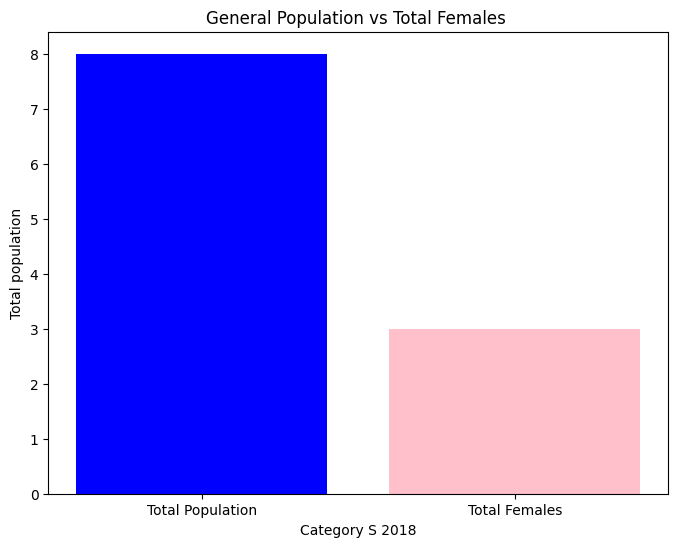

In [ ]:
# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category S 2018")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


All categories are present in the DataFrame.


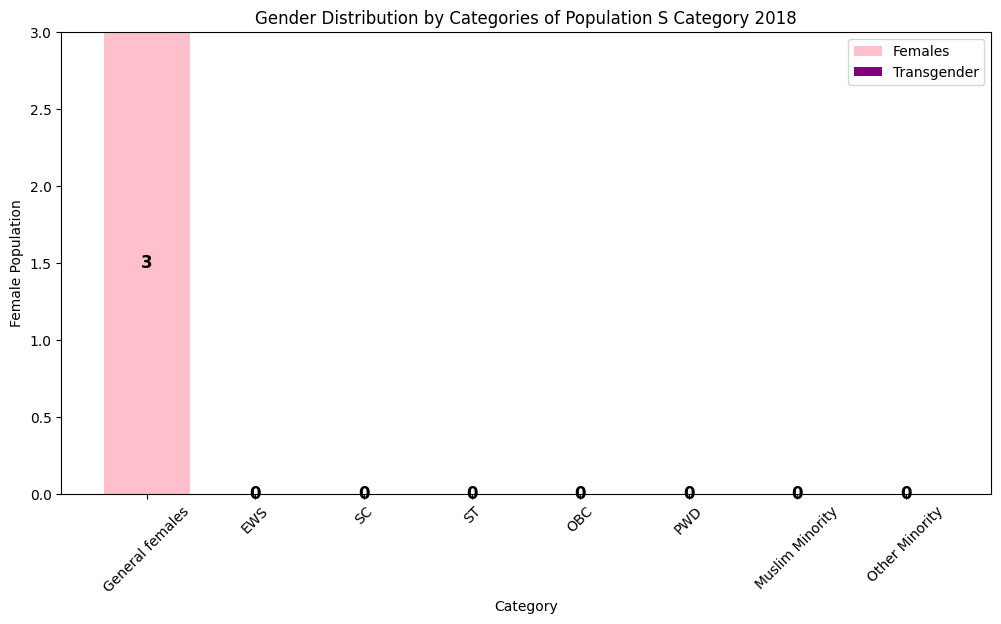

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Corresponding variables for females and transgenders
female_columns = [
    "total_female", "total_ews_female", "total_sc_female", "total_st_female",
    "total_obc_female", "pwd_total_females", "muslim_minority_total_females", "other_minority_total_females"
]

transgender_columns = [
    "total_total_transgender", "total_ews_transgender", "total_sc_transgender", "total_st_transgender",
    "total_obc_transgender", "pwd_total_transgender", "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Check if all the columns exist in df
existing_females = [col for col in female_columns if col in df.columns]
existing_transgenders = [col for col in transgender_columns if col in df.columns]

# Identify missing columns
missing_females = [col for col in female_columns if col not in df.columns]
missing_transgenders = [col for col in transgender_columns if col not in df.columns]

# Print missing categories if any
if missing_females or missing_transgenders:
    print("The following categories are missing from the DataFrame and will not be included in the plot:")
    if missing_females:
        print("Missing female category columns:", missing_females)
    if missing_transgenders:
        print("Missing transgender category columns:", missing_transgenders)
else:
    print("All categories are present in the DataFrame.")

# Define the female and transgender counts using only existing columns
females = [df[col].sum() for col in existing_females]
transgenders = [df[col].sum() for col in existing_transgenders]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories[:len(females)], females, color="pink", label="Females")
bars2 = plt.bar(categories[:len(transgenders)], transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel("Female Population")
plt.title("Gender Distribution by Categories of Population S Category 2018")
plt.legend()
plt.xticks(rotation=45)
plt.show()


### 2018 U

Load the dataset

In [ ]:
# Define the path to your file in Colab's storage
file_path = '/content/2018/Block-6-all-enrollment_U.csv'  # Update with your actual file name

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

In [ ]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,8,3,0,3,3,0,0,304,195,0
1,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,10,4,0,0,0,0,0,322,213,0
2,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,0,0,0,0,0,0,0,129,71,0
3,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,0,0,0,0,0,0,0,35,24,0
4,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,9,7,0,0,0,0,0,185,104,0


Analysis

In [ ]:
total_sum = df['total'].sum()
print(total_sum)

6946179


UG population filtering

In [ ]:
# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'programme' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'programme'
    df['discipline'] = df['discipline'].str.strip()
    df['programme'] = df['programme'].str.strip()

    # Convert to lowercase for better matching
    df['discipline'] = df['discipline'].str.lower()
    df['programme'] = df['programme'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("economics", na=False)]

    # Further filter for 'programme' matching 'B.A.(Hons)-Bachelor of Arts (Honors)' or variants
    df_filtered = df_filtered[df_filtered['programme'].str.contains(r'\bb\.a', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 70176
Number of rows after filtering: 153
     aishe_code  survey_year institution_category           state   district  \
2638     U-0035         2018                    U  Andhra Pradesh  Anantapur   
2665     U-0035         2018                    U  Andhra Pradesh  Anantapur   
2677     U-0035         2018                    U  Andhra Pradesh  Anantapur   
3605     U-0049         2018                    U           Assam     Kamrup   
3666     U-0049         2018                    U           Assam     Kamrup   

      block  pincode location              institute_type  ownership_status  \
2638    NaN   515134    Urban  Deemed University-Private                NaN   
2665    NaN   515134    Urban  Deemed University-Private                NaN   
2677    NaN   515134    Urban  Deemed University-Private                NaN   
3605    NaN   782402    Urban   State Private University                NaN   
3666    NaN   782402    Urban   State Private University  

In [ ]:
df = df_filtered

Summary Statistics

In [ ]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total"
]

# Check which variables exist in the dataframe
existing_vars = [var for var in variables if var in df_filtered.columns]
missing_vars = [var for var in variables if var not in df_filtered.columns]

# Print missing variables
if missing_vars:
    print("The following variables are missing from the DataFrame and will not be included in the summary statistics:\n")
    print(missing_vars)
else:
    print("All variables are present in the DataFrame.")

# Use only the existing variables for summary statistics
summary_stats = df_filtered[existing_vars].describe()

# Print results
print("\nSummary Statistics for Concerned Variables:\n")
print(summary_stats)


All variables are present in the DataFrame.

Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count     153.000000            153.000000                      153.0   
mean       16.130719              7.954248                        0.0   
std        27.163175             13.429808                        0.0   
min         0.000000              0.000000                        0.0   
25%         0.000000              0.000000                        0.0   
50%         6.000000              3.000000                        0.0   
75%        20.000000              9.000000                        0.0   
max       143.000000             82.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count             153.0                  153.0       153.000000   
mean                0.0                    0.0         0.790850   
std                 0.0                    0.0     

In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


Gender Share in Total Population:

Total Population (UG Economics): 3,690
Total Females: 1,776 (48.13%)
Total Transgender Individuals: 0 (0.00%)


In [ ]:
# Compute total dataset population
total_population = df["total"].sum()

# Compute total for each category
total_ews = df["total_ews_total"].sum()
total_sc = df["total_sc"].sum()
total_st = df["total_st"].sum()
total_obc = df["total_obc"].sum()
total_pwd = df["pwd_total"].sum()
total_muslims = df["muslim_minority_total"].sum()
total_other_minorities = df["other_minority_total"].sum()

# Compute total females for each category (new variables assigned)
total_female_ews = df["total_ews_female"].sum()
total_female_sc = df["total_sc_female"].sum()
total_female_st = df["total_st_female"].sum()
total_female_obc = df["total_obc_female"].sum()
total_female_pwd = df["pwd_total_females"].sum()
total_female_muslims = df["muslim_minority_total_females"].sum()
total_female_other_minorities = df["other_minority_total_females"].sum()

# Compute shares
female_ews_share = (total_female_ews / total_ews) * 100 if total_ews != 0 else 0
female_sc_share = (total_female_sc / total_sc) * 100 if total_sc != 0 else 0
female_st_share = (total_female_st / total_st) * 100 if total_st != 0 else 0
female_obc_share = (total_female_obc / total_obc) * 100 if total_obc != 0 else 0
female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd != 0 else 0
female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims != 0 else 0
female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities != 0 else 0

# Print results
print("\nCategory-wise Population Breakdown:\n")
print(f"Total Dataset Population: {total_population:,}")

print(f"\nTotal EWS (UG Economics): {total_ews:,}")
print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

print(f"\nTotal SC (UG Economics): {total_sc:,}")
print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

print(f"\nTotal ST (UG Economics): {total_st:,}")
print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

print(f"\nTotal OBC (UG Economics): {total_obc:,}")
print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")



Category-wise Population Breakdown:

Total Dataset Population: 3,690

Total EWS (UG Economics): 0
Total Female EWS: 0 (0.00%)

Total SC (UG Economics): 283
Total Female SC: 121 (42.76%)

Total ST (UG Economics): 352
Total Female ST: 180 (51.14%)

Total OBC (UG Economics): 568
Total Female OBC: 251 (44.19%)

Total PWD (UG Economics): 6
Total Female PWD: 2 (33.33%)

Total Muslims (UG Economics): 179
Total Female Muslim Minority: 81 (45.25%)

Total Other Minorities (UG Economics): 205
Total Female Other Minority: 123 (60.00%)


Results

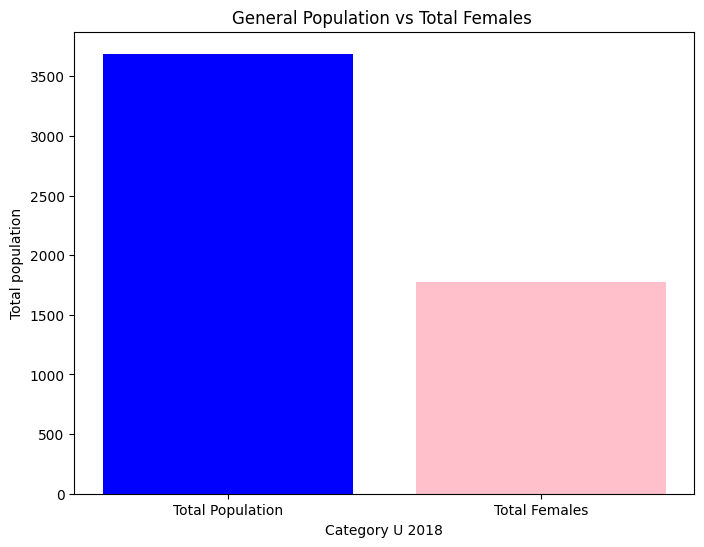

In [ ]:
# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category U 2018")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


All categories are present in the DataFrame.


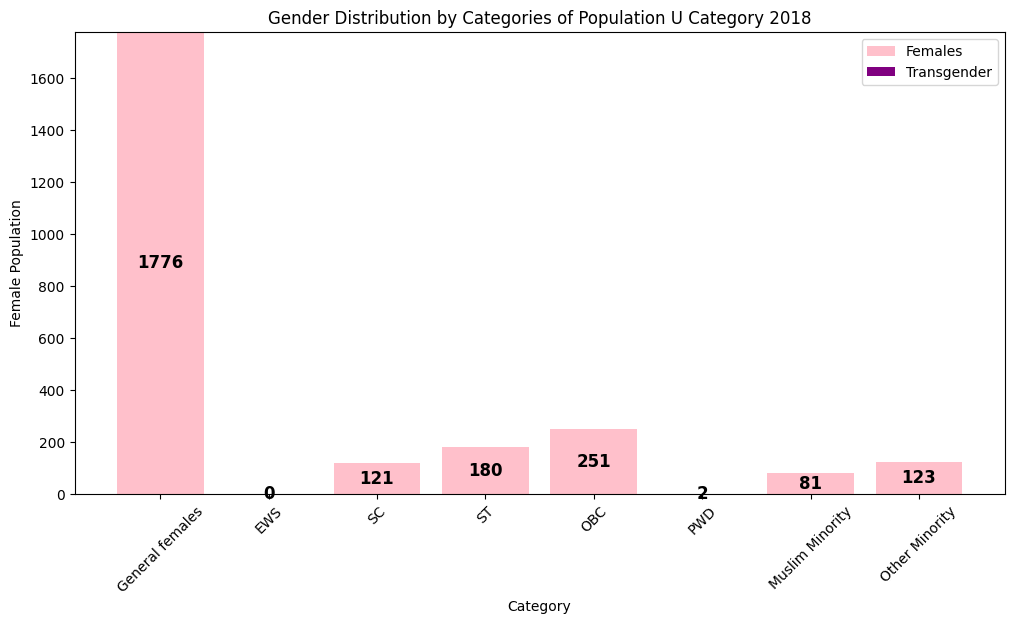

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Corresponding variables for females and transgenders
female_columns = [
    "total_female", "total_ews_female", "total_sc_female", "total_st_female",
    "total_obc_female", "pwd_total_females", "muslim_minority_total_females", "other_minority_total_females"
]

transgender_columns = [
    "total_total_transgender", "total_ews_transgender", "total_sc_transgender", "total_st_transgender",
    "total_obc_transgender", "pwd_total_transgender", "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Check if all the columns exist in df
existing_females = [col for col in female_columns if col in df.columns]
existing_transgenders = [col for col in transgender_columns if col in df.columns]

# Identify missing columns
missing_females = [col for col in female_columns if col not in df.columns]
missing_transgenders = [col for col in transgender_columns if col not in df.columns]

# Print missing categories if any
if missing_females or missing_transgenders:
    print("The following categories are missing from the DataFrame and will not be included in the plot:")
    if missing_females:
        print("Missing female category columns:", missing_females)
    if missing_transgenders:
        print("Missing transgender category columns:", missing_transgenders)
else:
    print("All categories are present in the DataFrame.")

# Define the female and transgender counts using only existing columns
females = [df[col].sum() for col in existing_females]
transgenders = [df[col].sum() for col in existing_transgenders]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories[:len(females)], females, color="pink", label="Females")
bars2 = plt.bar(categories[:len(transgenders)], transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel("Female Population")
plt.title("Gender Distribution by Categories of Population U Category 2018")
plt.legend()
plt.xticks(rotation=45)
plt.show()


## 2017

### 2017 C

Load the dataset

In [ ]:
# Define the path to your file in Colab's storage
file_path = '/content/2017/Block-6-all-enrollment.csv'  # Update with your actual file name

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

<ipython-input-106-7a94cc5e04ab>:5: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [ ]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
1,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
2,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
3,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,0,0,0
4,C-1000,2018,C,Gujarat,Rajkot,NaN,360005,Urban,Affiliated College,NaN,...,0,0,0,0,0,0,0,236,136,0


Analysis

In [ ]:
total_sum = df['total'].sum()
print(total_sum)

UG population filtering

In [ ]:
# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'programme' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'programme'
    df['discipline'] = df['discipline'].str.strip()
    df['programme'] = df['programme'].str.strip()

    # Convert to lowercase for better matching
    df['discipline'] = df['discipline'].str.lower()
    df['programme'] = df['programme'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("economics", na=False)]

    # Further filter for 'programme' matching 'B.A.(Hons)-Bachelor of Arts (Honors)' or variants
    df_filtered = df_filtered[df_filtered['programme'].str.contains(r'\bb\.a', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 400488
Number of rows after filtering: 2596
     aishe_code  survey_year institution_category    state     district  \
5526    C-10639         2018                    C  Haryana  Yamunanagar   
5540    C-10639         2018                    C  Haryana  Yamunanagar   
5555    C-10639         2018                    C  Haryana  Yamunanagar   
5569    C-10642         2018                    C  Haryana      Panipat   
5582    C-10642         2018                    C  Haryana      Panipat   

      block pincode location      institute_type  ownership_status  ...  \
5526    NaN  135001    Urban  Affiliated College               NaN  ...   
5540    NaN  135001    Urban  Affiliated College               NaN  ...   
5555    NaN  135001    Urban  Affiliated College               NaN  ...   
5569    NaN  132103    Urban  Affiliated College               NaN  ...   
5582    NaN  132103    Urban  Affiliated College               NaN  ...   

     muslim_minority_total mus

In [ ]:
df = df_filtered

Summary Statistics

In [ ]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total"
]

# Check which variables exist in the dataframe
existing_vars = [var for var in variables if var in df_filtered.columns]
missing_vars = [var for var in variables if var not in df_filtered.columns]

# Print missing variables
if missing_vars:
    print("The following variables are missing from the DataFrame and will not be included in the summary statistics:\n")
    print(missing_vars)
else:
    print("All variables are present in the DataFrame.")

# Use only the existing variables for summary statistics
summary_stats = df_filtered[existing_vars].describe()

# Print results
print("\nSummary Statistics for Concerned Variables:\n")
print(summary_stats)


All variables are present in the DataFrame.

Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count    2596.000000           2596.000000                     2596.0   
mean       11.067797              5.614792                        0.0   
std        17.450509              9.753272                        0.0   
min         0.000000              0.000000                        0.0   
25%         0.000000              0.000000                        0.0   
50%         4.000000              2.000000                        0.0   
75%        14.000000              6.000000                        0.0   
max       265.000000             92.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count            2596.0                 2596.0      2596.000000   
mean                0.0                    0.0         1.520031   
std                 0.0                    0.0     

In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


Gender Share in Total Population:

Total Population (UG Economics): 85,617
Total Females): 38,305 (44.74%)
Total Transgender Individuals: 0 (0.00%)


In [ ]:
# Compute total dataset population
total_population = df["total"].sum()

# Compute total for each category
total_ews = df["total_ews_total"].sum()
total_sc = df["total_sc"].sum()
total_st = df["total_st"].sum()
total_obc = df["total_obc"].sum()
total_pwd = df["pwd_total"].sum()
total_muslims = df["muslim_minority_total"].sum()
total_other_minorities = df["other_minority_total"].sum()

# Compute total females for each category (new variables assigned)
total_female_ews = df["total_ews_female"].sum()
total_female_sc = df["total_sc_female"].sum()
total_female_st = df["total_st_female"].sum()
total_female_obc = df["total_obc_female"].sum()
total_female_pwd = df["pwd_total_females"].sum()
total_female_muslims = df["muslim_minority_total_females"].sum()
total_female_other_minorities = df["other_minority_total_females"].sum()

# Compute shares
female_ews_share = (total_female_ews / total_ews) * 100 if total_ews != 0 else 0
female_sc_share = (total_female_sc / total_sc) * 100 if total_sc != 0 else 0
female_st_share = (total_female_st / total_st) * 100 if total_st != 0 else 0
female_obc_share = (total_female_obc / total_obc) * 100 if total_obc != 0 else 0
female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd != 0 else 0
female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims != 0 else 0
female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities != 0 else 0

# Print results
print("\nCategory-wise Population Breakdown:\n")
print(f"Total Dataset Population: {total_population:,}")

print(f"\nTotal EWS (UG Economics): {total_ews:,}")
print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

print(f"\nTotal SC (UG Economics): {total_sc:,}")
print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

print(f"\nTotal ST (UG Economics): {total_st:,}")
print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

print(f"\nTotal OBC (UG Economics): {total_obc:,}")
print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")


Results

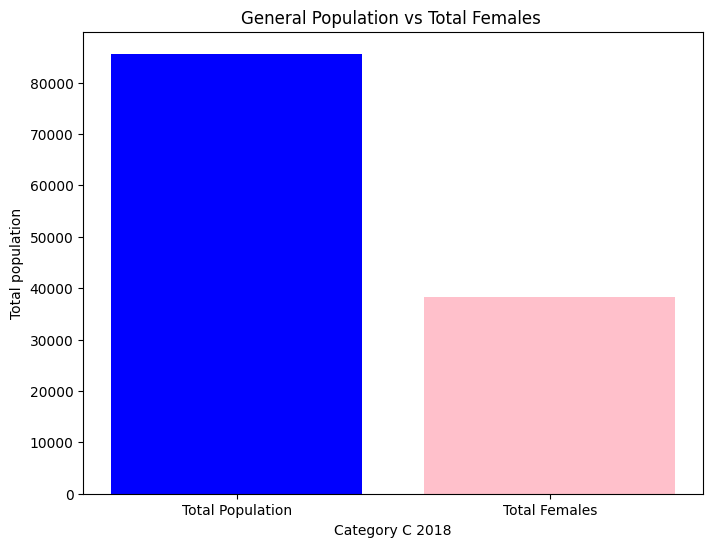

In [ ]:
# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category C 2018")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


All categories are present in the DataFrame.


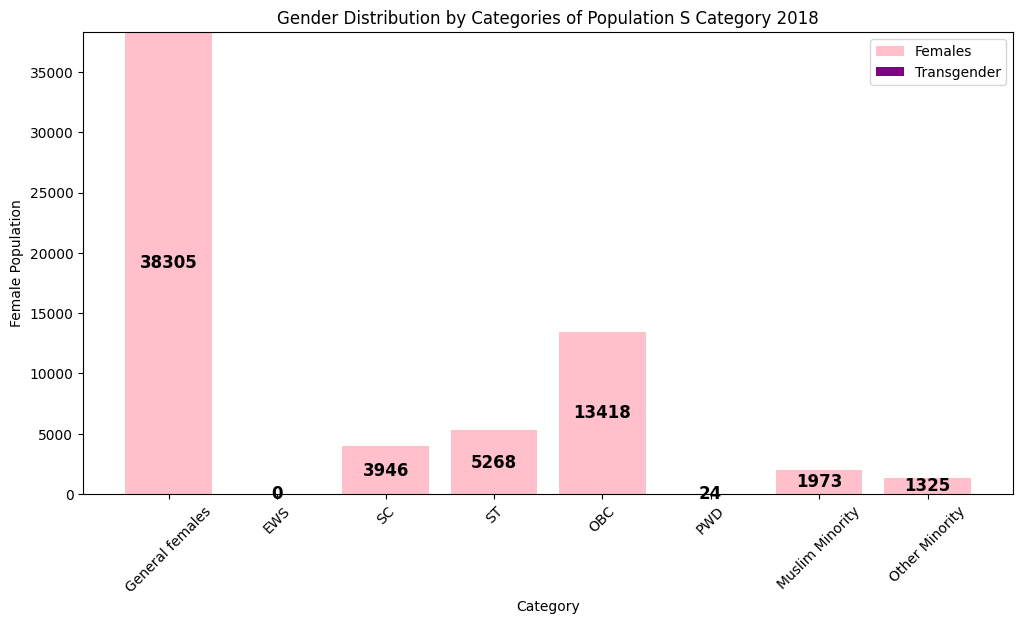

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Corresponding variables for females and transgenders
female_columns = [
    "total_female", "total_ews_female", "total_sc_female", "total_st_female",
    "total_obc_female", "pwd_total_females", "muslim_minority_total_females", "other_minority_total_females"
]

transgender_columns = [
    "total_total_transgender", "total_ews_transgender", "total_sc_transgender", "total_st_transgender",
    "total_obc_transgender", "pwd_total_transgender", "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Check if all the columns exist in df
existing_females = [col for col in female_columns if col in df.columns]
existing_transgenders = [col for col in transgender_columns if col in df.columns]

# Identify missing columns
missing_females = [col for col in female_columns if col not in df.columns]
missing_transgenders = [col for col in transgender_columns if col not in df.columns]

# Print missing categories if any
if missing_females or missing_transgenders:
    print("The following categories are missing from the DataFrame and will not be included in the plot:")
    if missing_females:
        print("Missing female category columns:", missing_females)
    if missing_transgenders:
        print("Missing transgender category columns:", missing_transgenders)
else:
    print("All categories are present in the DataFrame.")

# Define the female and transgender counts using only existing columns
females = [df[col].sum() for col in existing_females]
transgenders = [df[col].sum() for col in existing_transgenders]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories[:len(females)], females, color="pink", label="Females")
bars2 = plt.bar(categories[:len(transgenders)], transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel("Female Population")
plt.title("Gender Distribution by Categories of Population S Category 2018")
plt.legend()
plt.xticks(rotation=45)
plt.show()


### 2018 s

Load the dataset

In [ ]:
# Define the path to your file in Colab's storage
file_path = '/content/2018/Block-6-enrollment_details_S.csv'  # Update with your actual file name

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

In [ ]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,S-100,2018,S,Gujarat,Ahmadabad,NaN,380058,Rural,PGDM Institutes,NaN,...,1,0,0,19,8,0,0,160,56,0
1,S-100,2018,S,Gujarat,Ahmadabad,NaN,380058,Rural,PGDM Institutes,NaN,...,7,4,0,0,0,0,0,106,50,0
2,S-10000,2018,S,Maharashtra,Solapur,NaN,413216,Urban,Teacher Training,NaN,...,0,0,0,0,0,0,0,35,23,0
3,S-10000,2018,S,Maharashtra,Solapur,NaN,413216,Urban,Teacher Training,NaN,...,0,0,0,0,0,0,0,58,47,0
4,S-10003,2018,S,Maharashtra,Gadchiroli,NaN,441208,Rural,Teacher Training,NaN,...,0,0,0,0,0,0,0,0,0,0


Analysis

In [ ]:
total_sum = df['total'].sum()
print(total_sum)

UG population filtering

In [ ]:
# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'programme' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'programme'
    df['discipline'] = df['discipline'].str.strip()
    df['programme'] = df['programme'].str.strip()

    # Convert to lowercase for better matching
    df['discipline'] = df['discipline'].str.lower()
    df['programme'] = df['programme'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("economics", na=False)]

    # Further filter for 'programme' matching 'B.A.(Hons)-Bachelor of Arts (Honors)' or variants
    df_filtered = df_filtered[df_filtered['programme'].str.contains(r'\bb\.a', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 48633
Number of rows after filtering: 3
      aishe_code  survey_year institution_category        state district  \
47067     S-9170         2018                    S  Maharashtra   Raigad   
47072     S-9170         2018                    S  Maharashtra   Raigad   
47087     S-9170         2018                    S  Maharashtra   Raigad   

       block  pincode location    institute_type  ownership_status  ...  \
47067    NaN   410201    Rural  Teacher Training               NaN  ...   
47072    NaN   410201    Rural  Teacher Training               NaN  ...   
47087    NaN   410201    Rural  Teacher Training               NaN  ...   

      muslim_minority_total  muslim_minority_total_females  \
47067                     0                              0   
47072                     0                              0   
47087                     0                              0   

      muslim_minority_total_transgender other_minority_total  \
47067            

In [ ]:
df = df_filtered

Summary Statistics

In [ ]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total"
]

# Check which variables exist in the dataframe
existing_vars = [var for var in variables if var in df_filtered.columns]
missing_vars = [var for var in variables if var not in df_filtered.columns]

# Print missing variables
if missing_vars:
    print("The following variables are missing from the DataFrame and will not be included in the summary statistics:\n")
    print(missing_vars)
else:
    print("All variables are present in the DataFrame.")

# Use only the existing variables for summary statistics
summary_stats = df_filtered[existing_vars].describe()

# Print results
print("\nSummary Statistics for Concerned Variables:\n")
print(summary_stats)


All variables are present in the DataFrame.

Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count       3.000000              3.000000                        3.0   
mean        2.666667              1.000000                        0.0   
std         3.055050              1.732051                        0.0   
min         0.000000              0.000000                        0.0   
25%         1.000000              0.000000                        0.0   
50%         2.000000              0.000000                        0.0   
75%         4.000000              1.500000                        0.0   
max         6.000000              3.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count               3.0                    3.0              3.0   
mean                0.0                    0.0              0.0   
std                 0.0                    0.0     

In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


Gender Share in Total Population:

Total Population (UG Economics): 8
Total Females: 3 (37.50%)
Total Transgender Individuals: 0 (0.00%)


In [ ]:
# Compute total dataset population
total_population = df["total"].sum()

# Compute total for each category
total_ews = df["total_ews_total"].sum()
total_sc = df["total_sc"].sum()
total_st = df["total_st"].sum()
total_obc = df["total_obc"].sum()
total_pwd = df["pwd_total"].sum()
total_muslims = df["muslim_minority_total"].sum()
total_other_minorities = df["other_minority_total"].sum()

# Compute total females for each category (new variables assigned)
total_female_ews = df["total_ews_female"].sum()
total_female_sc = df["total_sc_female"].sum()
total_female_st = df["total_st_female"].sum()
total_female_obc = df["total_obc_female"].sum()
total_female_pwd = df["pwd_total_females"].sum()
total_female_muslims = df["muslim_minority_total_females"].sum()
total_female_other_minorities = df["other_minority_total_females"].sum()

# Compute shares
female_ews_share = (total_female_ews / total_ews) * 100 if total_ews != 0 else 0
female_sc_share = (total_female_sc / total_sc) * 100 if total_sc != 0 else 0
female_st_share = (total_female_st / total_st) * 100 if total_st != 0 else 0
female_obc_share = (total_female_obc / total_obc) * 100 if total_obc != 0 else 0
female_pwd_share = (total_female_pwd / total_pwd) * 100 if total_pwd != 0 else 0
female_muslim_share = (total_female_muslims / total_muslims) * 100 if total_muslims != 0 else 0
female_other_minority_share = (total_female_other_minorities / total_other_minorities) * 100 if total_other_minorities != 0 else 0

# Print results
print("\nCategory-wise Population Breakdown:\n")
print(f"Total Dataset Population: {total_population:,}")

print(f"\nTotal EWS (UG Economics): {total_ews:,}")
print(f"Total Female EWS: {total_female_ews:,} ({female_ews_share:.2f}%)")

print(f"\nTotal SC (UG Economics): {total_sc:,}")
print(f"Total Female SC: {total_female_sc:,} ({female_sc_share:.2f}%)")

print(f"\nTotal ST (UG Economics): {total_st:,}")
print(f"Total Female ST: {total_female_st:,} ({female_st_share:.2f}%)")

print(f"\nTotal OBC (UG Economics): {total_obc:,}")
print(f"Total Female OBC: {total_female_obc:,} ({female_obc_share:.2f}%)")

print(f"\nTotal PWD (UG Economics): {total_pwd:,}")
print(f"Total Female PWD: {total_female_pwd:,} ({female_pwd_share:.2f}%)")

print(f"\nTotal Muslims (UG Economics): {total_muslims:,}")
print(f"Total Female Muslim Minority: {total_female_muslims:,} ({female_muslim_share:.2f}%)")

print(f"\nTotal Other Minorities (UG Economics): {total_other_minorities:,}")
print(f"Total Female Other Minority: {total_female_other_minorities:,} ({female_other_minority_share:.2f}%)")


Results

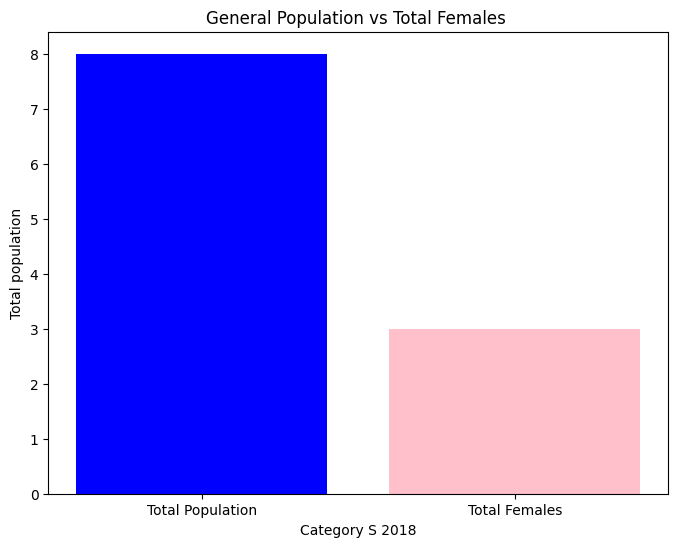

In [ ]:
# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category S 2018")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


All categories are present in the DataFrame.


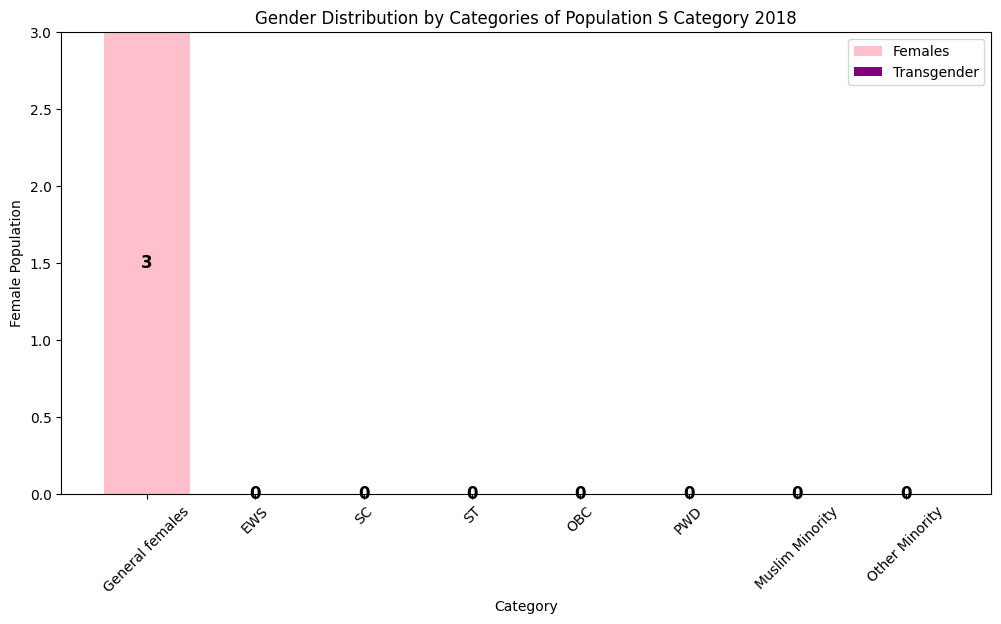

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Corresponding variables for females and transgenders
female_columns = [
    "total_female", "total_ews_female", "total_sc_female", "total_st_female",
    "total_obc_female", "pwd_total_females", "muslim_minority_total_females", "other_minority_total_females"
]

transgender_columns = [
    "total_total_transgender", "total_ews_transgender", "total_sc_transgender", "total_st_transgender",
    "total_obc_transgender", "pwd_total_transgender", "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Check if all the columns exist in df
existing_females = [col for col in female_columns if col in df.columns]
existing_transgenders = [col for col in transgender_columns if col in df.columns]

# Identify missing columns
missing_females = [col for col in female_columns if col not in df.columns]
missing_transgenders = [col for col in transgender_columns if col not in df.columns]

# Print missing categories if any
if missing_females or missing_transgenders:
    print("The following categories are missing from the DataFrame and will not be included in the plot:")
    if missing_females:
        print("Missing female category columns:", missing_females)
    if missing_transgenders:
        print("Missing transgender category columns:", missing_transgenders)
else:
    print("All categories are present in the DataFrame.")

# Define the female and transgender counts using only existing columns
females = [df[col].sum() for col in existing_females]
transgenders = [df[col].sum() for col in existing_transgenders]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories[:len(females)], females, color="pink", label="Females")
bars2 = plt.bar(categories[:len(transgenders)], transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel("Female Population")
plt.title("Gender Distribution by Categories of Population S Category 2018")
plt.legend()
plt.xticks(rotation=45)
plt.show()


### 2018 U

Load the dataset

In [ ]:
# Define the path to your file in Colab's storage
file_path = '/content/2018/Block-6-all-enrollment_U.csv'  # Update with your actual file name

# Load the dataset from Colab storage
df = pd.read_csv(file_path)

In [ ]:
df.head(
)

,aishe_code,survey_year,institution_category,state,district,block,pincode,location,institute_type,ownership_status,...,muslim_minority_total,muslim_minority_total_females,muslim_minority_total_transgender,other_minority_total,other_minority_total_females,other_minority_total_transgender,seats_earmarked_total,total,total_female,total_total_transgender
0,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,8,3,0,3,3,0,0,304,195,0
1,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,10,4,0,0,0,0,0,322,213,0
2,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,0,0,0,0,0,0,0,129,71,0
3,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,0,0,0,0,0,0,0,35,24,0
4,U-0001,2018,U,Andhra Pradesh,West Godavari,NaN,534101,Rural,State Public University,NaN,...,9,7,0,0,0,0,0,185,104,0


Analysis

In [ ]:
total_sum = df['total'].sum()
print(total_sum)

UG population filtering

In [ ]:
# Count of rows before filtering
initial_count = df.shape[0]

# Ensure columns exist
if 'discipline' in df.columns and 'programme' in df.columns:
    # Remove leading and trailing spaces in 'discipline' and 'programme'
    df['discipline'] = df['discipline'].str.strip()
    df['programme'] = df['programme'].str.strip()

    # Convert to lowercase for better matching
    df['discipline'] = df['discipline'].str.lower()
    df['programme'] = df['programme'].str.lower()

    # Filter for 'discipline' containing "economics" in any form
    df_filtered = df[df['discipline'].str.contains("economics", na=False)]

    # Further filter for 'programme' matching 'B.A.(Hons)-Bachelor of Arts (Honors)' or variants
    df_filtered = df_filtered[df_filtered['programme'].str.contains(r'\bb\.a', na=False, regex=True)]

    # Count of rows after filtering
    filtered_count = df_filtered.shape[0]

    # Display results
    print(f"Initial number of rows: {initial_count}")
    print(f"Number of rows after filtering: {filtered_count}")
    print(df_filtered.head())

else:
    print("Error: 'discipline' or 'programme' column not found in the dataset.")


Initial number of rows: 70176
Number of rows after filtering: 153
     aishe_code  survey_year institution_category           state   district  \
2638     U-0035         2018                    U  Andhra Pradesh  Anantapur   
2665     U-0035         2018                    U  Andhra Pradesh  Anantapur   
2677     U-0035         2018                    U  Andhra Pradesh  Anantapur   
3605     U-0049         2018                    U           Assam     Kamrup   
3666     U-0049         2018                    U           Assam     Kamrup   

      block  pincode location              institute_type  ownership_status  \
2638    NaN   515134    Urban  Deemed University-Private                NaN   
2665    NaN   515134    Urban  Deemed University-Private                NaN   
2677    NaN   515134    Urban  Deemed University-Private                NaN   
3605    NaN   782402    Urban   State Private University                NaN   
3666    NaN   782402    Urban   State Private University  

In [ ]:
df = df_filtered

Summary Statistics

In [ ]:
# Select relevant variables for summary statistics
variables = [
    "general_total", "general_total_female", "general_total_transgender",
    "total_ews_female", "total_ews_transgender", "total_sc_female", "total_sc_transgender",
    "total_st_female", "total_st_transgender", "total_obc_female", "total_obc_transgender",
    "pwd_total_females", "pwd_total_transgender", "muslim_minority_total_females",
    "muslim_minority_total_transgender", "other_minority_total_females",
    "other_minority_total_transgender", "total_female", "total_total_transgender", "total"
]

# Check which variables exist in the dataframe
existing_vars = [var for var in variables if var in df_filtered.columns]
missing_vars = [var for var in variables if var not in df_filtered.columns]

# Print missing variables
if missing_vars:
    print("The following variables are missing from the DataFrame and will not be included in the summary statistics:\n")
    print(missing_vars)
else:
    print("All variables are present in the DataFrame.")

# Use only the existing variables for summary statistics
summary_stats = df_filtered[existing_vars].describe()

# Print results
print("\nSummary Statistics for Concerned Variables:\n")
print(summary_stats)


All variables are present in the DataFrame.

Summary Statistics for Concerned Variables:

       general_total  general_total_female  general_total_transgender  \
count     153.000000            153.000000                      153.0   
mean       16.130719              7.954248                        0.0   
std        27.163175             13.429808                        0.0   
min         0.000000              0.000000                        0.0   
25%         0.000000              0.000000                        0.0   
50%         6.000000              3.000000                        0.0   
75%        20.000000              9.000000                        0.0   
max       143.000000             82.000000                        0.0   

       total_ews_female  total_ews_transgender  total_sc_female  \
count             153.0                  153.0       153.000000   
mean                0.0                    0.0         0.790850   
std                 0.0                    0.0     

In [ ]:
# List of only female-related variables
female_variables = [
    "general_total_female", "total_ews_female", "total_sc_female",
    "total_st_female", "total_obc_female", "pwd_total_females",
    "muslim_minority_total_females", "other_minority_total_females"
]

# List of transgender-related variables
transgender_variables = [
    "general_total_transgender", "total_ews_transgender", "total_sc_transgender",
    "total_st_transgender", "total_obc_transgender", "pwd_total_transgender",
    "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Compute total sum
total_population = df["total"].sum()
total_females_excluding_variable = df["total_female"].sum()
total_transgender = df["total_total_transgender"].sum()

# Compute shares
female_share = (total_females_excluding_variable / total_population) * 100
transgender_share = (total_transgender / total_population) * 100

# Print results
print("\nGender Share in Total Population:\n")
print(f"Total Population (UG Economics): {total_population:,}")
print(f"Total Females: {total_females_excluding_variable:,} ({female_share:.2f}%)")
print(f"Total Transgender Individuals: {total_transgender:,} ({transgender_share:.2f}%)")


Gender Share in Total Population:

Total Population (UG Economics): 3,690
Total Females: 1,776 (48.13%)
Total Transgender Individuals: 0 (0.00%)


Results

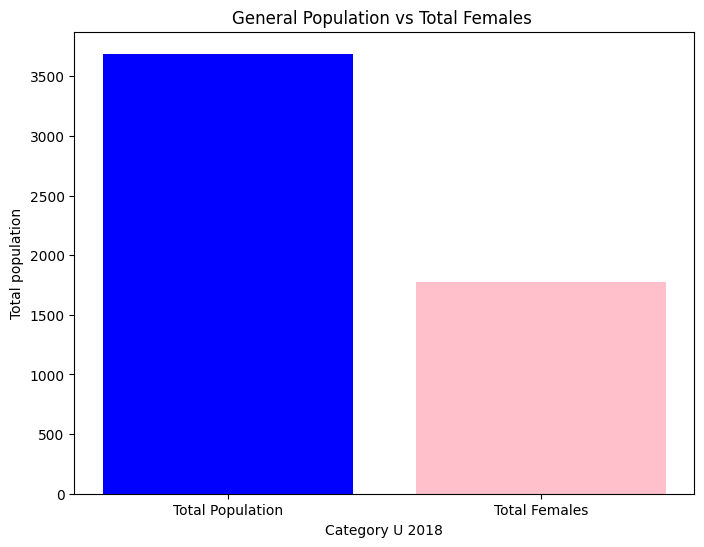

In [ ]:
# Bar chart for total population vs calculated total females
plt.figure(figsize=(8, 6))
plt.bar(["Total Population", "Total Females"],
        [total_population, total_females_excluding_variable],
        color=["blue", "pink"])
plt.xlabel("Category U 2018")
plt.ylabel("Total population")
plt.title("General Population vs Total Females ")
plt.show()


All categories are present in the DataFrame.


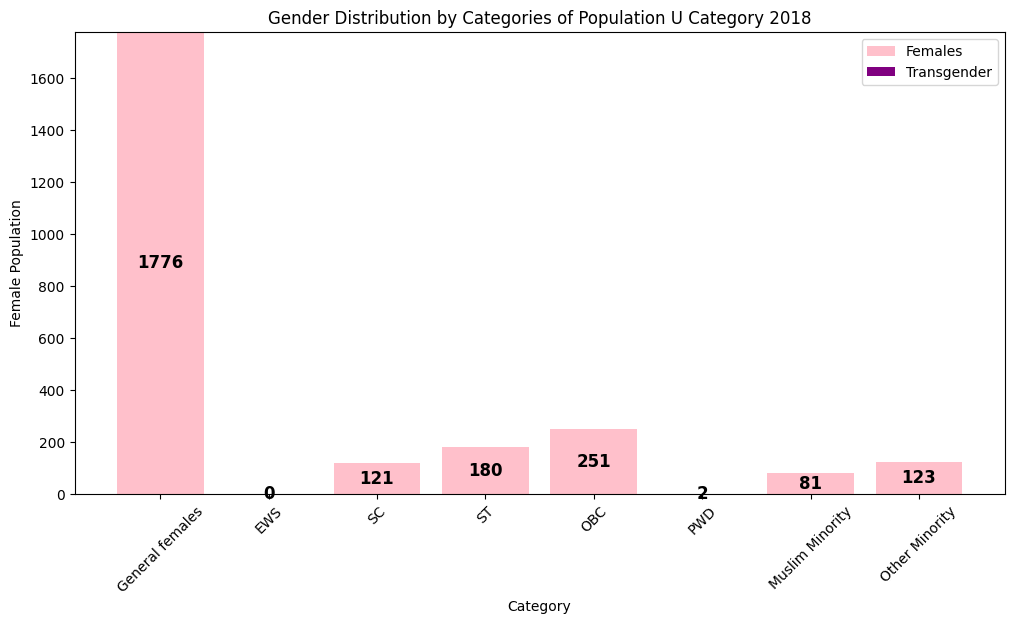

In [ ]:
import matplotlib.pyplot as plt

# Updated categories
categories = [
    "General females", "EWS", "SC", "ST", "OBC", "PWD",
    "Muslim Minority", "Other Minority"
]

# Corresponding variables for females and transgenders
female_columns = [
    "total_female", "total_ews_female", "total_sc_female", "total_st_female",
    "total_obc_female", "pwd_total_females", "muslim_minority_total_females", "other_minority_total_females"
]

transgender_columns = [
    "total_total_transgender", "total_ews_transgender", "total_sc_transgender", "total_st_transgender",
    "total_obc_transgender", "pwd_total_transgender", "muslim_minority_total_transgender", "other_minority_total_transgender"
]

# Check if all the columns exist in df
existing_females = [col for col in female_columns if col in df.columns]
existing_transgenders = [col for col in transgender_columns if col in df.columns]

# Identify missing columns
missing_females = [col for col in female_columns if col not in df.columns]
missing_transgenders = [col for col in transgender_columns if col not in df.columns]

# Print missing categories if any
if missing_females or missing_transgenders:
    print("The following categories are missing from the DataFrame and will not be included in the plot:")
    if missing_females:
        print("Missing female category columns:", missing_females)
    if missing_transgenders:
        print("Missing transgender category columns:", missing_transgenders)
else:
    print("All categories are present in the DataFrame.")

# Define the female and transgender counts using only existing columns
females = [df[col].sum() for col in existing_females]
transgenders = [df[col].sum() for col in existing_transgenders]

# Plot stacked bar chart
plt.figure(figsize=(12, 6))
bars1 = plt.bar(categories[:len(females)], females, color="pink", label="Females")
bars2 = plt.bar(categories[:len(transgenders)], transgenders, bottom=females, color="purple", label="Transgender")

# Annotate bars with values
for bar, value in zip(bars1, females):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() / 2, str(value), ha='center', va='center', fontsize=12, color='black', fontweight='bold')

for bar, female_value, transgender_value in zip(bars2, females, transgenders):
    if transgender_value > 0:  # Only annotate if there are transgender individuals
        plt.text(bar.get_x() + bar.get_width()/2, female_value + (transgender_value / 2), str(transgender_value), ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.xlabel("Category")
plt.ylabel("Female Population")
plt.title("Gender Distribution by Categories of Population U Category 2018")
plt.legend()
plt.xticks(rotation=45)
plt.show()
